# KG-GT v2: dual-stream token model

Three reported outputs:

- **K (kinematics-led)**: kinematic stream only. Judged on accuracy.
- **E (EEG only)**: EEG stream only. Judged against shuffled-EEG and swapped-EEG nulls.
- **F (fused)**: K held fixed plus a gated EEG correction. The gate starts at zero.

Everything runs on 50 Hz tokens with 8 s windows; predictions are interpolated back to 500 Hz and scored
against the same target and test series as `main_1stage.ipynb`. Outputs go to `outputs/checkpoints_v2/`,
`results/v2/` and `outputs/interpretability_v2/`; the baseline's files are only read.

**Acceptance criteria**

1. K: mean VAF above 75.5 % and mean r above 0.869 (the kinematics-only reference).
2. Magnitude: light- and middle-weight height ratios within 0.95-1.05, per-lift correlation at a fixed weight
   above the baseline's, rest level no worse.
3. E: EEG-only r above both nulls; 0.47 is the number to beat.
4. F: if F does not beat K against the null, the result is "EEG adds nothing beyond kinematics". That is an accepted outcome.
5. Budget: the V2-BUDGET cell passes and prints the projected run time before training.

**Interpretability (cell V2-INTERP)**

The model mixes information between time steps, electrodes, muscles and streams only through recorded
attention layers (plus a 5-tap input convolution with a known footprint), so every output value can be
traced back through all layers. For a window centred on each lift event of the test series the cell gives:

- **attention rollout** through every layer (the same for all muscles),
- **attention flow** (maximum flow through the same layers),
- **gradient-weighted rollout**, specific to one muscle and one time point,
- the attention of every single layer and head, input shares from gradient x input (kinematic features,
  history features, EEG bands), and the exact parts of each output (K = K_base x gain, F = relu(K + EEG correction)),
- a contrast against rest windows with a permutation test,
- two checks of the maps themselves: a **deletion** check (does removing the top-ranked inputs move the output
  more than removing random ones?) and a **weight-shuffle** check (does the map change when the learned weights
  are destroyed?).

**How to read the results**

- **Mixed precision** is chosen by measurement: the V2-BUDGET cell times a training step with mixed precision on
  and off and keeps the faster setting that fits in memory. On some GPUs mixed precision is the slower one.
- **The F verdict is one test over all muscles** (the mean over muscles against the swapped-EEG null). The
  per-muscle p-values are descriptive. Beating the nulls shows that the EEG is time-locked to the task;
  artefacts that are locked to the lift would pass the same test, so it does not prove a cortical origin.
- **Rollout and flow** show where information could have come from, and they are the same for all muscles of a
  stream. The gradient-weighted maps and gradient x input are specific to one muscle. The deletion and
  weight-shuffle checks say which view to trust.

In [1]:
# V2-SETUP
import copy, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

from main.dataloader import emg_channel_names, describe_split
from main.preprocessing_emg_kin import compute_muscle_edge_prior, kin_feature_names
from v2 import data as D
from v2.config import CONFIG_V2
from v2.evaluate import baseline_comparison, evaluate_subject
from v2.interp.report import interpret_subject
from v2.model import build_model, count_parameters
from v2.smoke import project_runtime
from v2.train import fit, weighted_stream_loss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [2]:
# V2-CONFIG
CONFIG = copy.deepcopy(CONFIG_V2)
subject_list = [1,2,3,4,5,6,7,8,9,10,11,12]                      # participants to run; each needs its cache built by main_1stage.ipynb
RESULTS = Path(CONFIG["outputs"]["results_dir"]); RESULTS.mkdir(parents=True, exist_ok=True)
CKPT = Path(CONFIG["outputs"]["checkpoint_dir"])
print(json.dumps({k: CONFIG[k] for k in ("tokens", "model", "loss", "training", "interp")}, indent=1))

{
 "tokens": {
  "window": 400,
  "stride": 100,
  "hop": 200
 },
 "model": {
  "d_model": 64,
  "n_heads": 4,
  "ffn_dim": 256,
  "dropout": 0.2,
  "kin_layers": 3,
  "eeg_layers": 2,
  "electrode_dim": 32,
  "electrode_gat_layers": 2,
  "electrode_dropout": 0.2,
  "node_dim": 32,
  "muscle_gat_layers": 2,
  "muscle_dropout": 0.1
 },
 "loss": {
  "w_main": 1.0,
  "w_ccc": 0.3,
  "w_lift": 0.5,
  "w_diff": 0.1,
  "huber_delta": 0.5
 },
 "training": {
  "lr": 0.001,
  "weight_decay": 0.01,
  "warmup_epochs": 5,
  "max_epochs": 150,
  "patience": 30,
  "batch_size": 32,
  "gradient_accumulation_steps": 1,
  "grad_clip_norm": 1.0,
  "use_amp": true,
  "smooth_window": 3,
  "seed": 42
 },
 "interp": {
  "residual": 0.5,
  "flow_bin": 4,
  "events": [
   "first_touch",
   "lift_off"
  ],
  "max_events": 6,
  "deletion_fractions": [
   0.05,
   0.1,
   0.2,
   0.4
  ],
  "n_random": 10,
  "n_perm": 1000,
  "seed": 42
 }
}


In [3]:
# V2-BUDGET
# A few forward/backward steps on RANDOM data: peak GPU memory, seconds per step, projected time for max_epochs.
# Trains nothing real and saves nothing. Needs the GPU free. Adjusts batch size / accumulation if memory is tight.
# On the GPU it measures mixed precision on and off and keeps the faster setting that fits in memory.
budget = project_runtime(CONFIG, device, n_windows=1100)
CONFIG["training"]["batch_size"] = budget["batch_size"]
CONFIG["training"]["gradient_accumulation_steps"] = budget["gradient_accumulation_steps"]
CONFIG["training"]["use_amp"] = budget["use_amp"]
print("measured settings (empty = out of memory):")
print(pd.DataFrame(budget["candidates"]).round(3).to_string(index=False, na_rep=""))
print(f"chosen: mixed precision {'on' if budget['use_amp'] else 'off'}, batch size {budget['batch_size']}, "
      f"accumulation {budget['gradient_accumulation_steps']}, peak memory {budget['peak_gb']} of {budget['total_gb']} GB, "
      f"{budget['parameters']:,} parameters")
print(f"projected time for {CONFIG['training']['max_epochs']} epochs: {budget['projected_minutes']:.1f} min")

measured settings (empty = out of memory):
 use_amp  batch_size  gradient_accumulation_steps  peak_gb  sec_per_step  projected_minutes  fits
    True          32                            1    2.705         0.946             81.303  True
   False          32                            1    3.462         0.293             25.205  True
chosen: mixed precision off, batch size 32, accumulation 1, peak memory 3.462 of 6.0 GB, 337,712 parameters
projected time for 150 epochs: 25.2 min


In [4]:
# V2-DATA
subject_data = {}
for p_id in subject_list:
    t0 = time.time(); subj = f"P{p_id}"
    cache = CONFIG["data"]["cache_dir"]
    tok = {s: [D.build_tokens(r, CONFIG) for r in D.load_split(cache, p_id, s)] for s in ("train", "val", "test")}
    norm = D.fit_norm(tok["train"])
    prior = compute_muscle_edge_prior([t["emg_full"] for t in tok["train"]])
    tc = CONFIG["tokens"]
    subject_data[subj] = dict(
        p_id=p_id, tokens=tok, norm=norm, muscle_prior=prior, names=emg_channel_names(p_id),
        train_ds=D.TokenWindows(tok["train"], norm, tc["window"], tc["stride"], random_offset=True, seed=CONFIG["training"]["seed"]),
        val_ds=D.TokenWindows(tok["val"], norm, tc["window"], tc["stride"]),
    )
    sd = subject_data[subj]
    print(f"{subj}: train windows {len(sd['train_ds'])}, val windows {len(sd['val_ds'])}, "
          f"holds per train series {[int(t['hold_id'].max()) for t in tok['train']]}, {time.time() - t0:.0f} s")
    print(describe_split(p_id))

P1: train windows 1074, val windows 112, holds per train series [34, 34, 28, 34, 34, 34], 37 s
P1 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:S, S3:B, S6:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:W, S5:B]  lifts=62
P2: train windows 1332, val windows 144, holds per train series [28, 34, 34, 34, 34, 34], 45 s
P2 stratified split (W=weight, S=surface, B=both varies):
  train [S1:B, S2:S, S3:W, S4:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S5:W, S6:B]  lifts=62
P3: train windows 1002, val windows 108, holds per train series [34, 28, 34, 34, 34, 34], 35 s
P3 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:B, S3:S, S5:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:B, S6:W]  lifts=62
P4: train windows 1052, val windows 118, holds per train series [34, 28, 34, 34, 34, 34], 37 s
P4 stratified split (W=weight, S=surface, B=both varies):
  train [S1:S, S2:B, S3:W, S6:S, S7:W, S8:W]  lifts=


=== P1: 337,712 parameters ===
  training already completed (76/150 epochs, bad K 3/30, bad E 30/30, bad V+K 30/30): training skipped
P1: 76 epochs, best K epoch 73, best E epoch 46, 0.0 min
P1: validation loss of E alone is lowest at epoch 38 (0.2417); E is saved from epoch 46 (0.2921), K from epoch 73
P1: combined best model, validation loss E + F 0.3529, K alone 0.0609, F alone 0.0607 -> F can be interpreted: yes


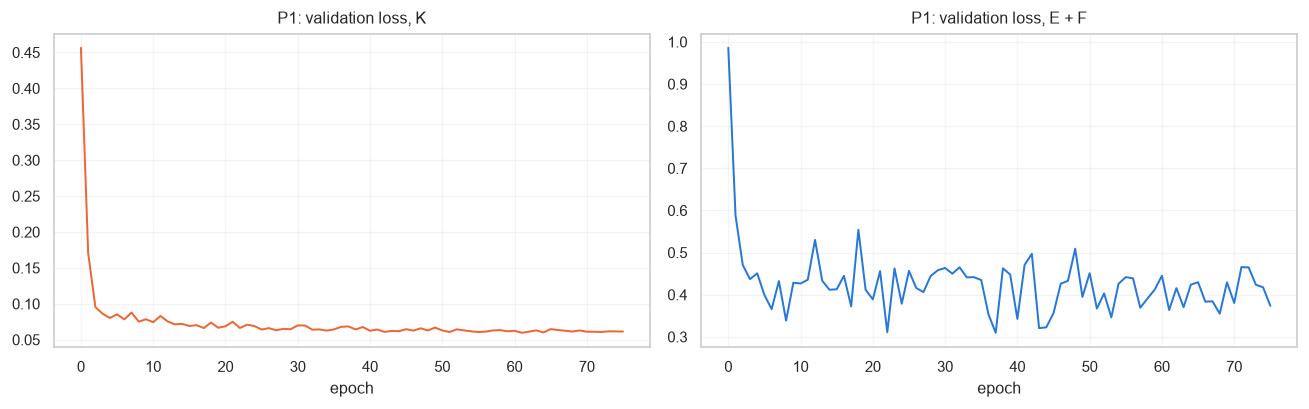


=== P2: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [02:15<31:35, 13.54s/ep, tr=0.4539, valK=0.0557, valE=0.2176, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0557 (best K ep 10)  val E+F 0.2176 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [04:35<30:21, 14.01s/ep, tr=0.3674, valK=0.0512, valE=0.2261, badK=0/30, badE=8/30, badVK=8/30]

  [best.pt] ep   20  val K 0.0512 (best K ep 20)  val E+F 0.2261 (best E ep 12)


...

  [best.pt] ep   30  val K 0.0520 (best K ep 24)  val E+F 0.2016 (best E ep 30)


  Epochs:  53%|█████▎    | 80/150 [18:17<16:08, 13.84s/ep, tr=0.2915, valK=0.0503, valE=0.1938, badK=3/30, badE=0/30, badVK=0/30]   

  [best.pt] ep   80  val K 0.0503 (best K ep 77)  val E+F 0.1938 (best E ep 80)


  Epochs:  73%|███████▎  | 109/150 [25:06<09:26, 13.82s/ep, tr=0.2786, valK=0.0493, valE=0.2066, badK=24/30, badE=30/30, badVK=3/30] 


  early stop: E (30/30) reached patience
  combined best model: val K 0.0494  val E+F 0.1927  (K from epoch 86, E and fusion from epoch 80: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P2  (best.pt, last.pt, history.json, metrics.*)
P2: 110 epochs, best K epoch 86, best E epoch 80, 25.1 min
P2: validation loss of E alone is lowest at epoch 44 (0.1365); E is saved from epoch 80 (0.1432), K from epoch 86
P2: combined best model, validation loss E + F 0.1927, K alone 0.0494, F alone 0.0495 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


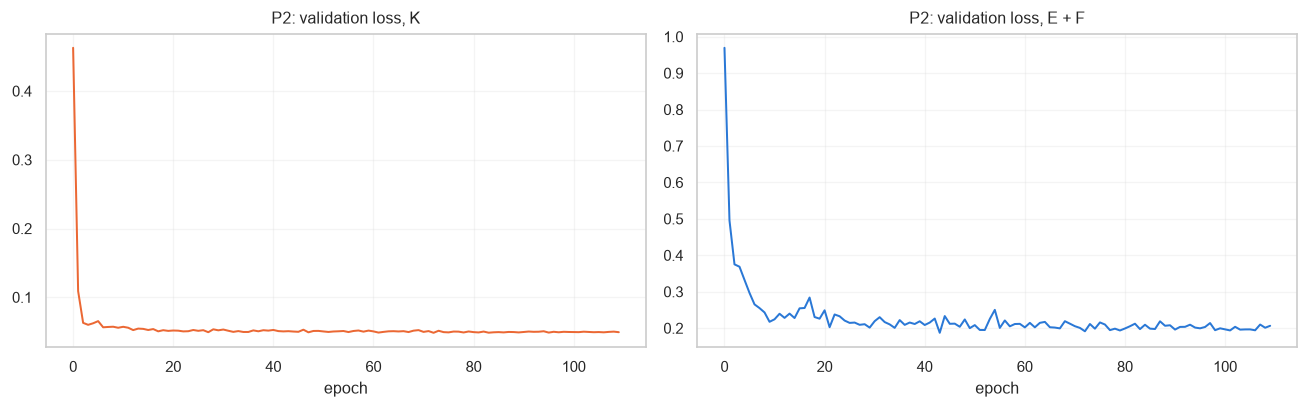


=== P3: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:42<24:00, 10.29s/ep, tr=0.4539, valK=0.0946, valE=0.3653, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0946 (best K ep 10)  val E+F 0.3653 (best E ep 10)


  Epochs:  40%|████      | 60/150 [10:30<15:46, 10.51s/ep, tr=0.3325, valK=0.0907, valE=0.3638, badK=30/30, badE=29/30, badVK=29/30]


  early stop: K (30/30) reached patience
  combined best model: val K 0.0889  val E+F 0.3322  (K from epoch 31, E and fusion from epoch 32: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P3  (best.pt, last.pt, history.json, metrics.*)
P3: 61 epochs, best K epoch 31, best E epoch 32, 10.5 min
P3: validation loss of E alone is lowest at epoch 31 (0.2366); E is saved from epoch 32 (0.2438), K from epoch 31
P3: combined best model, validation loss E + F 0.3322, K alone 0.0889, F alone 0.0884 -> F can be interpreted: yes


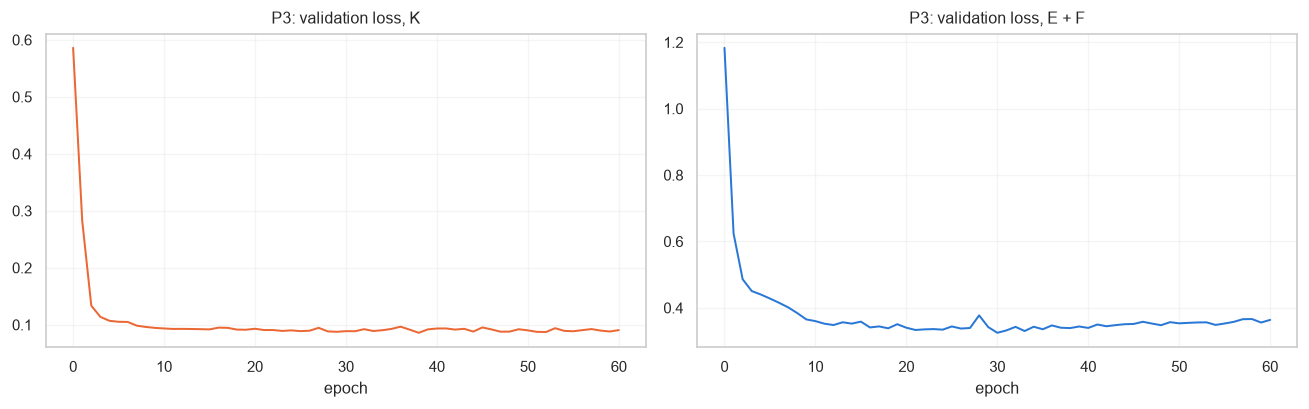


=== P4: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:48<25:25, 10.89s/ep, tr=0.3149, valK=0.0657, valE=0.2904, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0657 (best K ep 10)  val E+F 0.2904 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [03:38<24:01, 11.09s/ep, tr=0.2693, valK=0.0627, valE=0.2427, badK=1/30, badE=0/30, badVK=0/30]

  [best.pt] ep   20  val K 0.0627 (best K ep 19)  val E+F 0.2427 (best E ep 20)


...

  [best.pt] ep   40  val K 0.0570 (best K ep 35)  val E+F 0.2299 (best E ep 40)


  Epochs:  33%|███▎      | 50/150 [09:08<18:33, 11.14s/ep, tr=0.2417, valK=0.0602, valE=0.2285, badK=3/30, badE=0/30, badVK=1/30]

  [best.pt] ep   50  val K 0.0602 (best K ep 47)  val E+F 0.2285 (best E ep 50)


  Epochs:  56%|█████▌    | 84/150 [15:29<12:10, 11.06s/ep, tr=0.2162, valK=0.0561, valE=0.2069, badK=30/30, badE=0/30, badVK=0/30]  


  early stop: K (30/30) reached patience
  combined best model: val K 0.0559  val E+F 0.2068  (K from epoch 55, E and fusion from epoch 85: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P4  (best.pt, last.pt, history.json, metrics.*)
P4: 85 epochs, best K epoch 55, best E epoch 85, 15.5 min
P4: validation loss of E alone is lowest at epoch 83 (0.1472); E is saved from epoch 85 (0.1509), K from epoch 55
P4: combined best model, validation loss E + F 0.2068, K alone 0.0559, F alone 0.0559 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


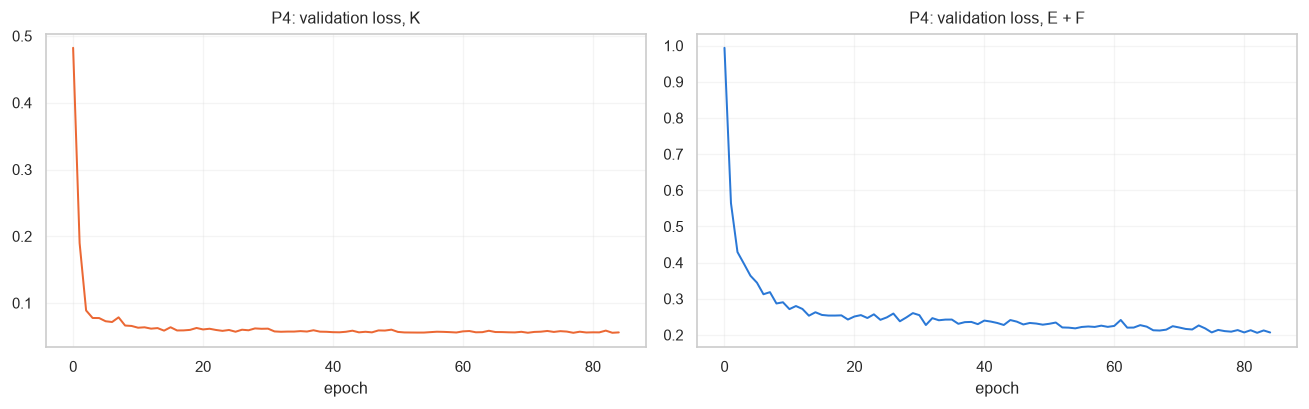


=== P5: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:56<27:10, 11.64s/ep, tr=0.4883, valK=0.1139, valE=0.3224, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.1139 (best K ep 10)  val E+F 0.3224 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [03:53<25:20, 11.69s/ep, tr=0.4452, valK=0.1068, valE=0.3013, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   20  val K 0.1068 (best K ep 20)  val E+F 0.3013 (best E ep 20)


...

  [best.pt] ep   30  val K 0.1069 (best K ep 30)  val E+F 0.2842 (best E ep 30)


  Epochs:  33%|███▎      | 50/150 [09:47<19:48, 11.89s/ep, tr=0.3992, valK=0.1057, valE=0.2790, badK=7/30, badE=0/30, badVK=0/30]

  [best.pt] ep   50  val K 0.1057 (best K ep 43)  val E+F 0.2790 (best E ep 50)


  Epochs:  56%|█████▌    | 84/150 [16:36<13:02, 11.86s/ep, tr=0.3715, valK=0.1060, valE=0.2771, badK=30/30, badE=8/30, badVK=8/30]  


  early stop: K (30/30) reached patience
  combined best model: val K 0.1049  val E+F 0.2711  (K from epoch 55, E and fusion from epoch 77: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P5  (best.pt, last.pt, history.json, metrics.*)
P5: 85 epochs, best K epoch 55, best E epoch 77, 16.6 min
P5: validation loss of E alone is lowest at epoch 75 (0.1641); E is saved from epoch 77 (0.1663), K from epoch 55
P5: combined best model, validation loss E + F 0.2711, K alone 0.1049, F alone 0.1048 -> F can be interpreted: yes


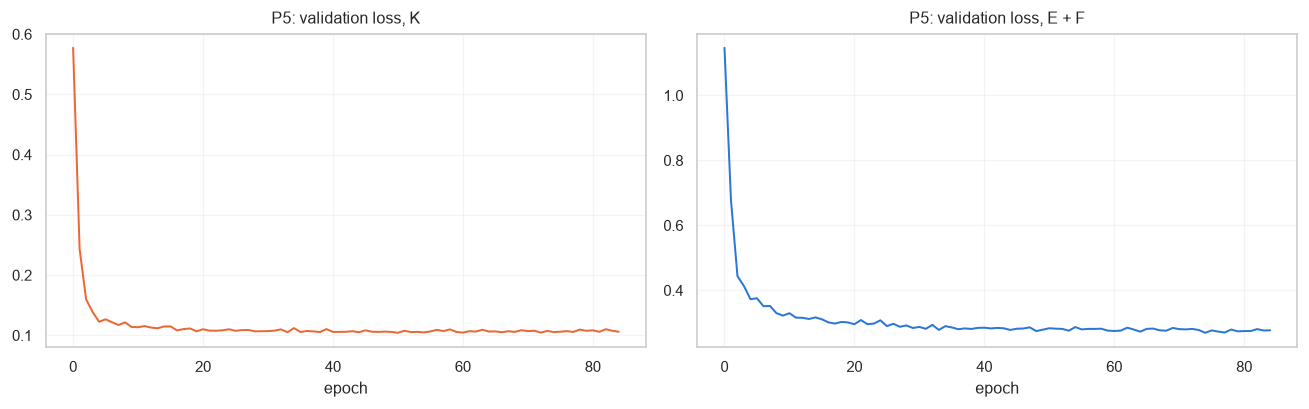


=== P6: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:59<28:14, 12.10s/ep, tr=0.4194, valK=0.0917, valE=0.3130, badK=3/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0917 (best K ep 7)  val E+F 0.3130 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [03:59<25:52, 11.94s/ep, tr=0.3596, valK=0.0802, valE=0.2634, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   20  val K 0.0802 (best K ep 20)  val E+F 0.2634 (best E ep 20)


  Epochs:  52%|█████▏    | 78/150 [15:33<14:21, 11.97s/ep, tr=0.2900, valK=0.0845, valE=0.2735, badK=30/30, badE=25/30, badVK=30/30]


  early stop: K (30/30), V+K (30/30) reached patience
  combined best model: val K 0.0805  val E+F 0.2478  (K from epoch 49, E and fusion from epoch 54: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P6  (best.pt, last.pt, history.json, metrics.*)
P6: 79 epochs, best K epoch 49, best E epoch 54, 15.6 min
P6: validation loss of E alone is lowest at epoch 39 (0.1672); E is saved from epoch 54 (0.1673), K from epoch 49
P6: combined best model, validation loss E + F 0.2478, K alone 0.0805, F alone 0.0806 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


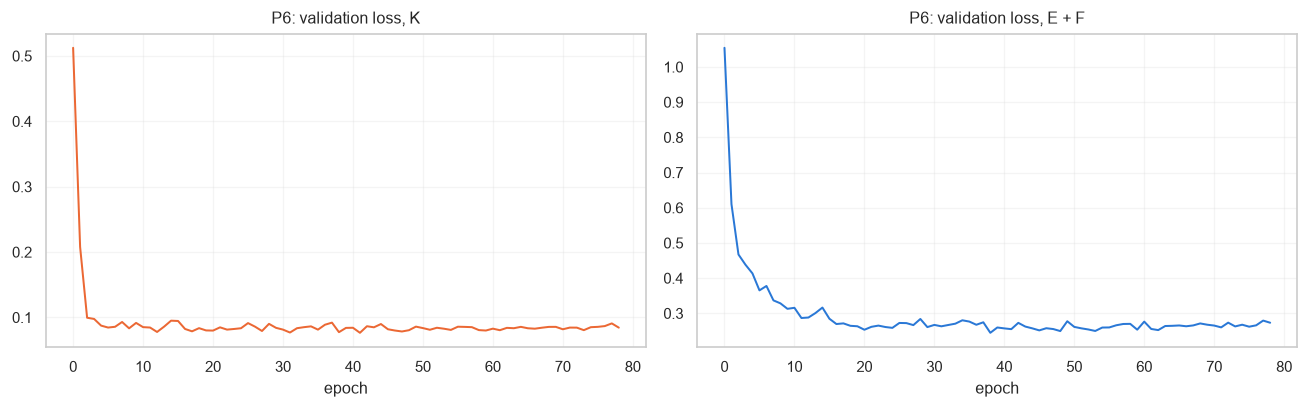


=== P7: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [02:11<30:57, 13.27s/ep, tr=0.3799, valK=0.0689, valE=0.2448, badK=2/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0689 (best K ep 8)  val E+F 0.2448 (best E ep 10)


  Epochs:  20%|██        | 30/150 [06:37<26:51, 13.43s/ep, tr=0.3135, valK=0.0623, valE=0.2391, badK=0/30, badE=8/30, badVK=8/30]

  [best.pt] ep   30  val K 0.0623 (best K ep 30)  val E+F 0.2391 (best E ep 22)


  Epochs:  44%|████▍     | 66/150 [14:36<18:35, 13.27s/ep, tr=0.2743, valK=0.0648, valE=0.2569, badK=29/30, badE=30/30, badVK=30/30]


  early stop: E (30/30), V+K (30/30) reached patience
  combined best model: val K 0.0599  val E+F 0.2030  (K from epoch 38, E and fusion from epoch 37: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P7  (best.pt, last.pt, history.json, metrics.*)
P7: 67 epochs, best K epoch 38, best E epoch 37, 14.6 min
P7: validation loss of E alone is lowest at epoch 37 (0.1430); E is saved from epoch 37 (0.1430), K from epoch 38
P7: combined best model, validation loss E + F 0.2030, K alone 0.0599, F alone 0.0599 -> F can be interpreted: yes


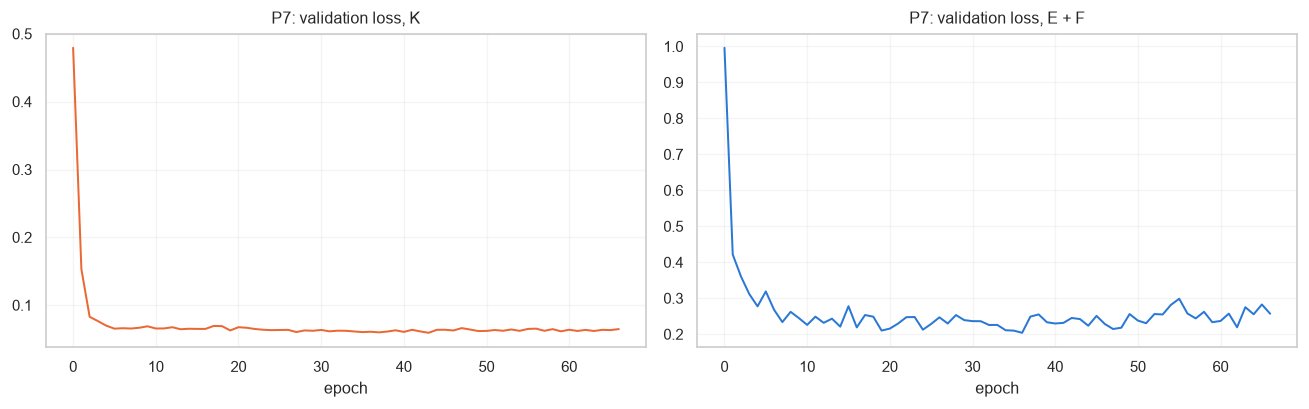


=== P8: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:45<24:41, 10.58s/ep, tr=0.4730, valK=0.1160, valE=0.3827, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.1160 (best K ep 10)  val E+F 0.3827 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [03:31<23:02, 10.64s/ep, tr=0.4274, valK=0.1064, valE=0.3314, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   20  val K 0.1064 (best K ep 20)  val E+F 0.3314 (best E ep 20)


  Epochs:  37%|███▋      | 56/150 [10:06<16:57, 10.82s/ep, tr=0.3715, valK=0.1114, valE=0.3108, badK=30/30, badE=14/30, badVK=14/30]


  early stop: K (30/30) reached patience
  combined best model: val K 0.1080  val E+F 0.2954  (K from epoch 27, E and fusion from epoch 43: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P8  (best.pt, last.pt, history.json, metrics.*)
P8: 57 epochs, best K epoch 27, best E epoch 43, 10.1 min
P8: validation loss of E alone is lowest at epoch 42 (0.1870); E is saved from epoch 43 (0.1873), K from epoch 27
P8: combined best model, validation loss E + F 0.2954, K alone 0.1080, F alone 0.1080 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


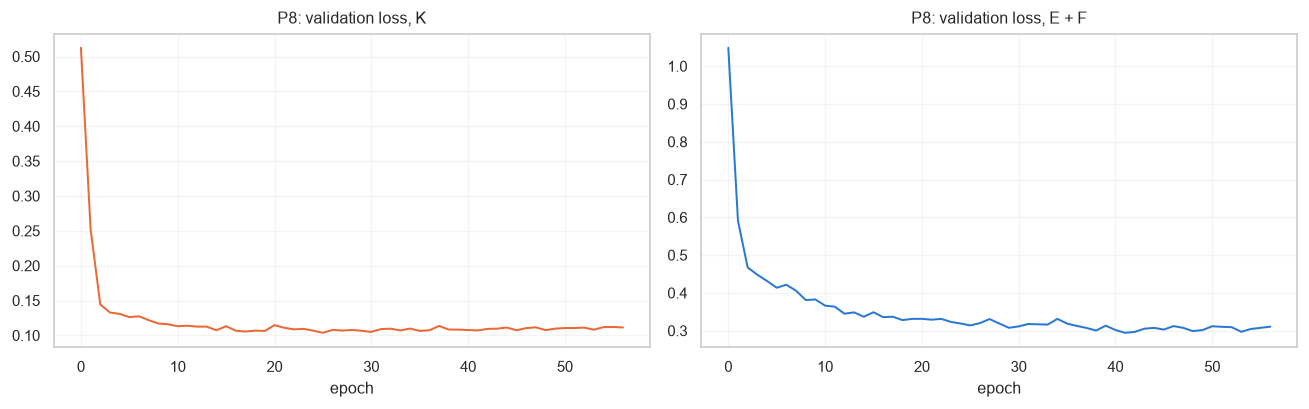


=== P9: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:52<26:16, 11.26s/ep, tr=0.4319, valK=0.0723, valE=0.3439, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0723 (best K ep 10)  val E+F 0.3439 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [03:44<24:26, 11.28s/ep, tr=0.3721, valK=0.0716, valE=0.3124, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   20  val K 0.0716 (best K ep 20)  val E+F 0.3124 (best E ep 20)


...

  [best.pt] ep   30  val K 0.0751 (best K ep 28)  val E+F 0.3090 (best E ep 30)


  Epochs:  27%|██▋       | 40/150 [07:28<20:24, 11.13s/ep, tr=0.3161, valK=0.0666, valE=0.2940, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   40  val K 0.0666 (best K ep 40)  val E+F 0.2940 (best E ep 40)


  Epochs:  46%|████▌     | 69/150 [13:02<15:19, 11.35s/ep, tr=0.2761, valK=0.0642, valE=0.3043, badK=0/30, badE=30/30, badVK=30/30] 


  [best.pt] ep   70  val K 0.0642 (best K ep 70)  val E+F 0.3043 (best E ep 40)
  early stop: E (30/30), V+K (30/30) reached patience
  combined best model: val K 0.0642  val E+F 0.2917  (K from epoch 70, E and fusion from epoch 40: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P9  (best.pt, last.pt, history.json, metrics.*)
P9: 70 epochs, best K epoch 70, best E epoch 40, 13.1 min
P9: validation loss of E alone is lowest at epoch 40 (0.2273); E is saved from epoch 40 (0.2273), K from epoch 70
P9: combined best model, validation loss E + F 0.2917, K alone 0.0642, F alone 0.0644 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


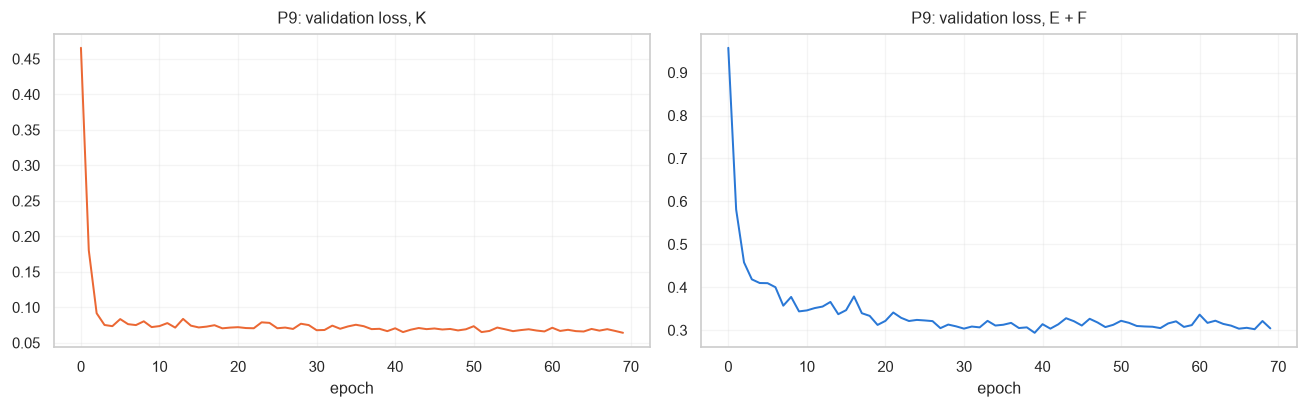


=== P10: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:54<26:42, 11.45s/ep, tr=0.3432, valK=0.0725, valE=0.2655, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0725 (best K ep 10)  val E+F 0.2655 (best E ep 10)


  Epochs:  45%|████▍     | 67/150 [13:01<16:08, 11.67s/ep, tr=0.2392, valK=0.0740, valE=0.2521, badK=19/30, badE=30/30, badVK=30/30]


  early stop: E (30/30), V+K (30/30) reached patience
  combined best model: val K 0.0714  val E+F 0.2246  (K from epoch 49, E and fusion from epoch 38: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P10  (best.pt, last.pt, history.json, metrics.*)
P10: 68 epochs, best K epoch 49, best E epoch 38, 13.0 min
P10: validation loss of E alone is lowest at epoch 37 (0.1501); E is saved from epoch 38 (0.1532), K from epoch 49
P10: combined best model, validation loss E + F 0.2246, K alone 0.0714, F alone 0.0715 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


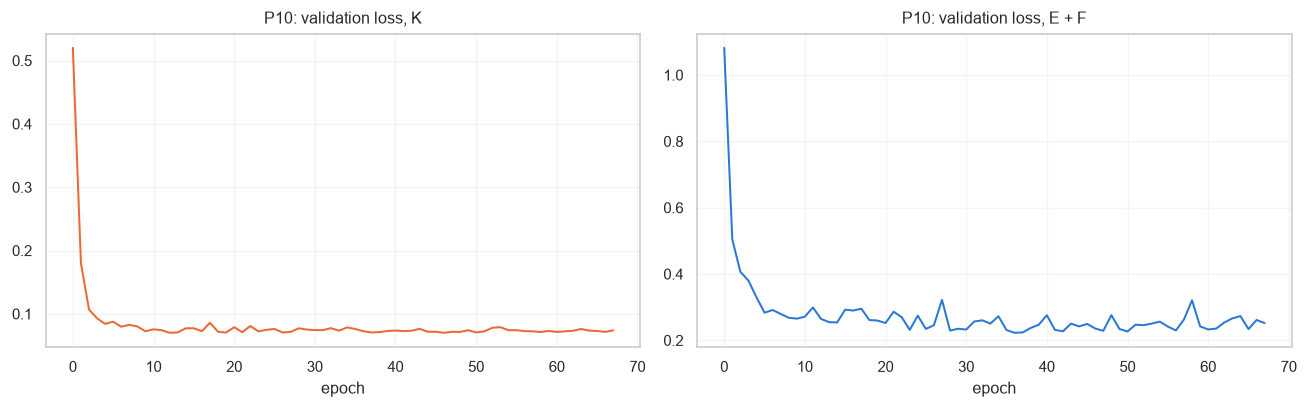


=== P11: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [01:57<27:27, 11.77s/ep, tr=0.3683, valK=0.0761, valE=0.3065, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0761 (best K ep 10)  val E+F 0.3065 (best E ep 10)


  Epochs:  13%|█▎        | 20/150 [03:58<26:10, 12.08s/ep, tr=0.3226, valK=0.0748, valE=0.2943, badK=1/30, badE=0/30, badVK=0/30]

  [best.pt] ep   20  val K 0.0748 (best K ep 19)  val E+F 0.2943 (best E ep 20)


  Epochs:  27%|██▋       | 40/150 [07:55<21:43, 11.85s/ep, tr=0.2894, valK=0.0731, valE=0.2556, badK=7/30, badE=0/30, badVK=0/30]  

  [best.pt] ep   40  val K 0.0731 (best K ep 33)  val E+F 0.2556 (best E ep 40)


  Epochs:  41%|████▏     | 62/150 [12:24<17:37, 12.01s/ep, tr=0.2727, valK=0.0823, valE=0.2805, badK=30/30, badE=7/30, badVK=7/30]


  early stop: K (30/30) reached patience
  combined best model: val K 0.0725  val E+F 0.2618  (K from epoch 33, E and fusion from epoch 56: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P11  (best.pt, last.pt, history.json, metrics.*)
P11: 63 epochs, best K epoch 33, best E epoch 56, 12.4 min
P11: validation loss of E alone is lowest at epoch 47 (0.1768); E is saved from epoch 56 (0.1893), K from epoch 33
P11: combined best model, validation loss E + F 0.2618, K alone 0.0725, F alone 0.0725 -> F can be interpreted: yes


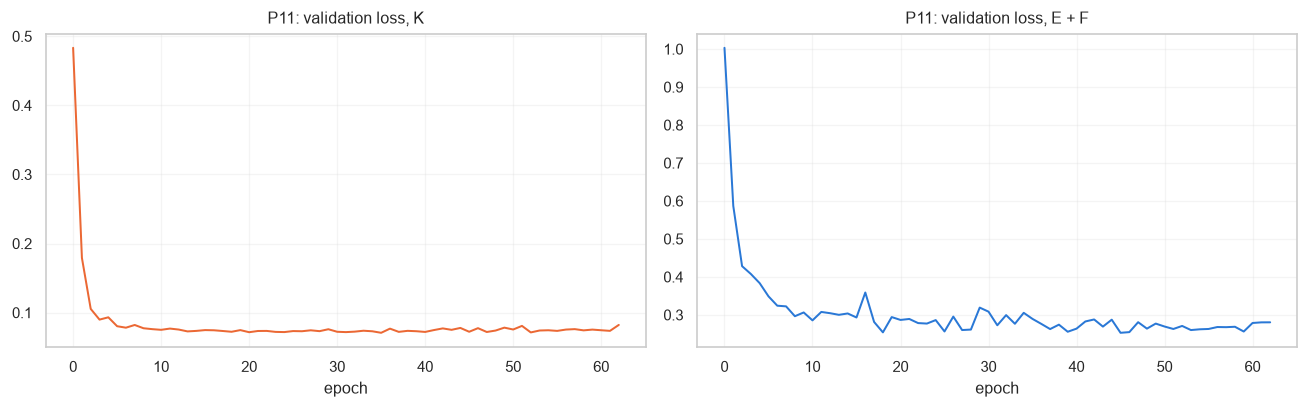


=== P12: 337,712 parameters ===


  Epochs:   7%|▋         | 10/150 [02:03<28:51, 12.36s/ep, tr=0.4349, valK=0.0765, valE=0.3295, badK=0/30, badE=0/30, badVK=0/30]

  [best.pt] ep   10  val K 0.0765 (best K ep 10)  val E+F 0.3295 (best E ep 10)


  Epochs:  27%|██▋       | 40/150 [08:14<23:02, 12.57s/ep, tr=0.3379, valK=0.0723, valE=0.2871, badK=21/30, badE=0/30, badVK=0/30]  

  [best.pt] ep   40  val K 0.0723 (best K ep 19)  val E+F 0.2871 (best E ep 40)


  Epochs:  32%|███▏      | 48/150 [10:06<21:28, 12.63s/ep, tr=0.3249, valK=0.0743, valE=0.3118, badK=30/30, badE=1/30, badVK=1/30]


  early stop: K (30/30) reached patience
  combined best model: val K 0.0711  val E+F 0.2767  (K from epoch 19, E and fusion from epoch 48: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2\P12  (best.pt, last.pt, history.json, metrics.*)
P12: 49 epochs, best K epoch 19, best E epoch 48, 10.1 min
P12: validation loss of E alone is lowest at epoch 46 (0.2029); E is saved from epoch 48 (0.2051), K from epoch 19
P12: combined best model, validation loss E + F 0.2767, K alone 0.0711, F alone 0.0716 -> F can be interpreted: NO (fusion and K come from different epochs and F is worse than K on validation)


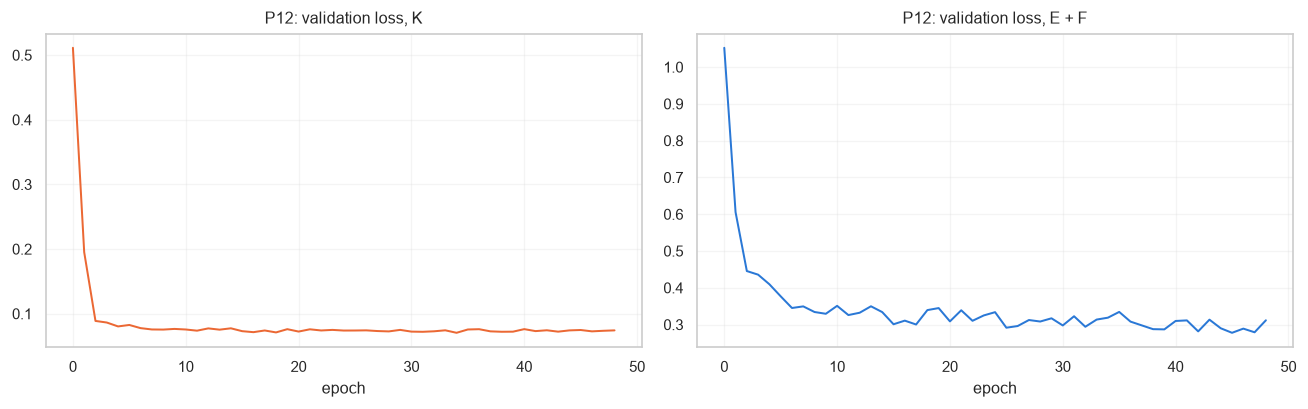

In [5]:
# V2-TRAIN
results = {}
for subj, sd in subject_data.items():
    t0 = time.time()
    torch.manual_seed(CONFIG["training"]["seed"])
    model = build_model(CONFIG, sd["muscle_prior"]).to(device)
    print(f"\n=== {subj}: {count_parameters(model):,} parameters ===")
    history = fit(model, sd["train_ds"], sd["val_ds"], CONFIG, device, CKPT / subj)
    ep_k, ep_e = history["best_epoch_kin"], history["best_epoch_eeg"]
    print(f"{subj}: {history['epochs_run']} epochs, best K epoch {ep_k}, best E epoch {ep_e}, {(time.time() - t0) / 60:.1f} min")
    # E and the fusion are saved at the epoch with the lowest smoothed E + F loss, which need not be E's own best epoch
    lc = CONFIG["loss"]
    e_alone = [weighted_stream_loss(c, "E", lc) for c in history["components"]]
    ep_alone = int(np.argmin(e_alone)) + 1
    print(f"{subj}: validation loss of E alone is lowest at epoch {ep_alone} ({e_alone[ep_alone - 1]:.4f}); "
          f"E is saved from epoch {ep_e} ({e_alone[ep_e - 1] if ep_e else float('nan'):.4f}), K from epoch {ep_k}")
    vc = history["val_combined"]                     # the saved model joins each stream's own best epoch
    l_k, l_f = weighted_stream_loss(vc["components"], "K", lc), weighted_stream_loss(vc["components"], "F", lc)
    differ = ep_k != ep_e
    fusion_checked = not (differ and l_f > l_k)      # False: this K and this fusion never met in training, and F lost
    print(f"{subj}: combined best model, validation loss E + F {vc['eeg']:.4f}, K alone {l_k:.4f}, F alone {l_f:.4f} "
          f"-> F can be interpreted: "
          + ("yes" if fusion_checked else "NO (fusion and K come from different epochs and F is worse than K on validation)"))
    results[subj] = dict(model=model, history=history, fusion_checked=fusion_checked)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(history["val_kin"], color="#eb6834"); ax[0].set_title(f"{subj}: validation loss, K"); ax[0].set_xlabel("epoch")
    ax[1].plot(history["val_eeg"], color="#2a78d6"); ax[1].set_title(f"{subj}: validation loss, E + F"); ax[1].set_xlabel("epoch")
    fig.tight_layout(); fig.savefig(RESULTS / f"history_{subj}.png", dpi=130); plt.show()

In [6]:
# V2-EVAL
tables = {k: [] for k in ("standard", "magnitude", "by_load", "ceiling", "nulls", "history")}
verdicts, n_pass = [], {"E": 0, "F": 0}
for subj, sd in subject_data.items():
    res = evaluate_subject(results[subj]["model"], sd["tokens"]["test"], sd["norm"], CONFIG, device, sd["p_id"], sd["names"])
    results[subj]["eval"] = res
    for k in tables:
        tables[k].append(res[k].assign(subject=subj))
    std = res["standard"]
    print(f"\n=== {subj} ===")
    print(std.pivot(index="muscle", columns="output", values="vaf").loc[sd["names"], ["K", "E", "F"]].round(1).to_string())
    print("mean r:", std.groupby("output").r.mean().round(3).to_dict(), "| mean VAF:", std.groupby("output").vaf.mean().round(1).to_dict())
    print(res["ceiling"].round(1).to_string(index=False))
    bl = res["by_load"]                              # acceptance criterion 2 for K: one row per test series and weight
    bl = bl[(bl["output"] == "K") & (bl["grouping"] == "CurW")].assign(value=lambda d: d["value"].astype(str))
    print("criterion 2, K: height ratio in the hold phase per test series and weight (value 1 = light, 2 = middle, 4 = heavy; "
          "0.95-1.05 wanted for light and middle):")
    print(bl.pivot(index=["series", "value", "n_lifts"], columns="muscle", values="height_ratio")[sd["names"]].round(3).to_string())
    print("criterion 2, K: correlation over lifts of the predicted and the real hold level at one weight (NaN below 4 lifts):")
    print(bl.pivot(index=["series", "value", "n_lifts"], columns="muscle", values="r_lift")[sd["names"]].round(3).to_string())
    n = res["nulls"]
    print("per muscle against the nulls (descriptive; the verdict below is one test over all muscles):")
    print(n[["muscle", "E_r", "E_r_shuffle_mean", "E_r_swap_mean", "E_p_swap", "dF_vaf", "dF_vaf_swap_mean", "dF_p_swap", "gate"]].round(3).to_string(index=False))
    v = res["verdict"]                               # mean over muscles against the per-draw means of the swap null
    f_beats_k = bool(v["dF_vaf_mean"] > 0 and np.isfinite(v["dF_p_swap"]) and v["dF_p_swap"] <= 0.05)
    f_verdict = "EEG adds information beyond kinematics" if f_beats_k else "EEG adds nothing beyond kinematics"
    fusion_checked = results[subj]["fusion_checked"]         # set by V2-TRAIN
    if not fusion_checked:
        f_verdict = "not interpretable (fusion and K come from different epochs and F is worse than K on validation)"
    n_pass["E"] += bool(np.isfinite(v["E_p_swap"]) and v["E_p_swap"] <= 0.05)
    n_pass["F"] += bool(f_beats_k and fusion_checked)
    print(f"E verdict: mean r {v['E_r_mean']:.3f}, p against the swap null {v['E_p_swap']:.3f}")
    print(f"F verdict: mean VAF gain over K {v['dF_vaf_mean']:.2f}, p against the swap null {v['dF_p_swap']:.3f} -> {f_verdict}")
    print(f"  ({v['n_null']} null draws, {v['n_distinct']} distinct, {v['n_blocks']} blocks; no p below 1 / blocks is possible)")
    verdicts.append({"subject": subj, **v, "F_verdict": f_verdict, "fusion_checked": fusion_checked})
    print("history check (K with the history of another test series, when there is one):")
    print(res["history"].round(1).to_string(index=False))
for k, parts in tables.items():
    pd.concat(parts, ignore_index=True).to_csv(RESULTS / f"{k}.csv", index=False)
pd.DataFrame(verdicts).to_csv(RESULTS / "verdict.csv", index=False)
print(f"\n{n_pass['F']} of {len(verdicts)} participants pass the F verdict, {n_pass['E']} of {len(verdicts)} pass E "
      f"(p against the swap null <= 0.05). Without any effect about 5 % pass by chance.")
print("saved tables to", RESULTS)


=== P1 ===
output     K     E     F
muscle                  
AD      91.4  48.1  91.3
BR      85.1  41.0  85.2
FD      69.2  28.9  69.4
ED      84.2  40.8  84.2
FDI     87.9  18.2  87.9
mean r: {'E': 0.623, 'F': 0.914, 'K': 0.914} | mean VAF: {'E': 35.4, 'F': 83.6, 'K': 83.6}
muscle  ceiling_vaf  modulation
    AD         92.3   20.700001
    BR         91.1    6.300000
    FD         86.9    4.400000
    ED         90.6    5.000000
   FDI         87.1    7.500000
criterion 2, K: height ratio in the hold phase per test series and weight (value 1 = light, 2 = middle, 4 = heavy; 0.95-1.05 wanted for light and middle):
muscle                   AD     BR     FD     ED    FDI
series value n_lifts                                   
4      1     11       1.001  0.976  0.921  0.973  0.974
       2     11       1.028  0.974  0.967  0.927  0.944
       4     12       0.962  0.859  0.753  0.916  1.062
       all   34       0.993  0.922  0.869  0.933  1.016
5      1     14       0.999  0.979  1.0

In [7]:
# V2-COMPARE
rows = []
for subj in subject_data:
    cmp_ = baseline_comparison(results[subj]["eval"]["standard"], subj, "results/magnitude_report_1stage.csv")
    if cmp_ is None:
        print(f"{subj}: no baseline row found"); continue
    rows.append(cmp_.assign(subject=subj))
    print(f"\n{subj}: baseline vs v2 K"); print(cmp_.round(3).to_string(index=False))
if rows:
    allc = pd.concat(rows, ignore_index=True)
    allc.to_csv(RESULTS / "baseline_comparison.csv", index=False)
    print("\nmean over participants and muscles: baseline VAF %.1f, v2 K VAF %.1f, baseline r %.3f, v2 K r %.3f"
          % (allc.baseline_vaf.mean(), allc.v2_K_vaf.mean(), allc.baseline_r.mean(), allc.v2_K_r.mean()))
    print(f"criterion 1 (K: mean VAF > 75.5 and mean r > 0.869), computed for {allc.subject.nunique()} of {len(subject_data)} "
          f"participants run here; the references 75.5 / 0.869 are means over all 12 participants:",
          bool(allc.v2_K_vaf.mean() > 75.5 and allc.v2_K_r.mean() > 0.869))


P1: baseline vs v2 K
muscle  baseline_r  v2_K_r  baseline_vaf  v2_K_vaf  d_vaf
    AD       0.945   0.956        88.441    91.364  2.924
    BR       0.915   0.925        83.345    85.113  1.768
    FD       0.777   0.832        59.802    69.243  9.441
    ED       0.896   0.918        78.132    84.194  6.062
   FDI       0.923   0.938        85.076    87.893  2.817

P2: baseline vs v2 K
muscle  baseline_r  v2_K_r  baseline_vaf  v2_K_vaf  d_vaf
    AD       0.870   0.876        73.727    76.435  2.708
    BR       0.941   0.949        86.158    89.899  3.742
    FD       0.828   0.850        68.194    71.630  3.436
    ED       0.945   0.952        88.712    90.536  1.823
   FDI       0.777   0.813        59.017    65.973  6.956

P3: baseline vs v2 K
muscle  baseline_r  v2_K_r  baseline_vaf  v2_K_vaf  d_vaf
    AD       0.955   0.960        90.366    92.199  1.833
    BR       0.884   0.900        78.100    80.586  2.486
    FD       0.485   0.565        19.217    23.719  4.502
    ED


=== P1: 25 figures and 8 tables in outputs\interpretability_v2\P1, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.822 0.862 0.822   0.751 1.095  0.000
    BR first_touch 60 0.636 0.740 0.637   0.563 1.129  0.001
    FD first_touch 60 0.601 0.700 0.604   0.503 1.196  0.003
    ED first_touch 60 0.733 0.777 0.733   0.651 1.127 -0.000
   FDI first_touch 60 0.384 0.669 0.384   0.322 1.190  0.000
    AD    lift_off 61 0.976 0.879 0.976   0.892 1.094 -0.000
    BR    lift_off 61 0.955 0.812 0.958   0.847 1.128  0.002
    FD    lift_off 61 0.741 0.747 0.745   0.620 1.194  0.004
    ED    lift_off 61 1.021 0.843 1.022   0.906 1.126  0.001
   FDI    lift_off 61 1.313 0.791 1.313   1.105 1.188 -0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

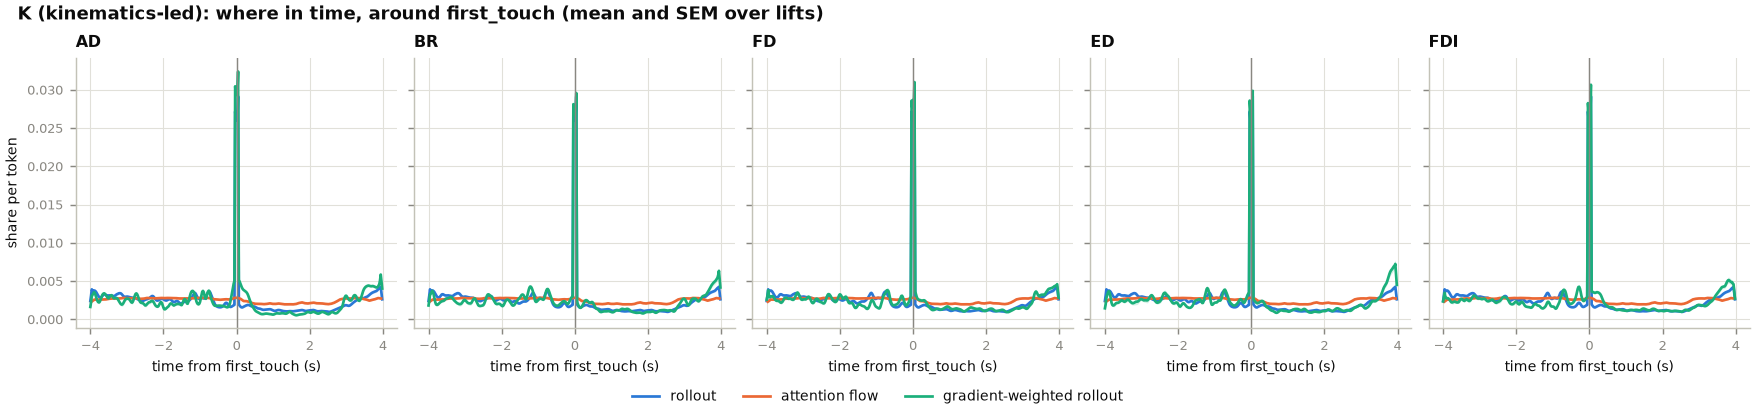

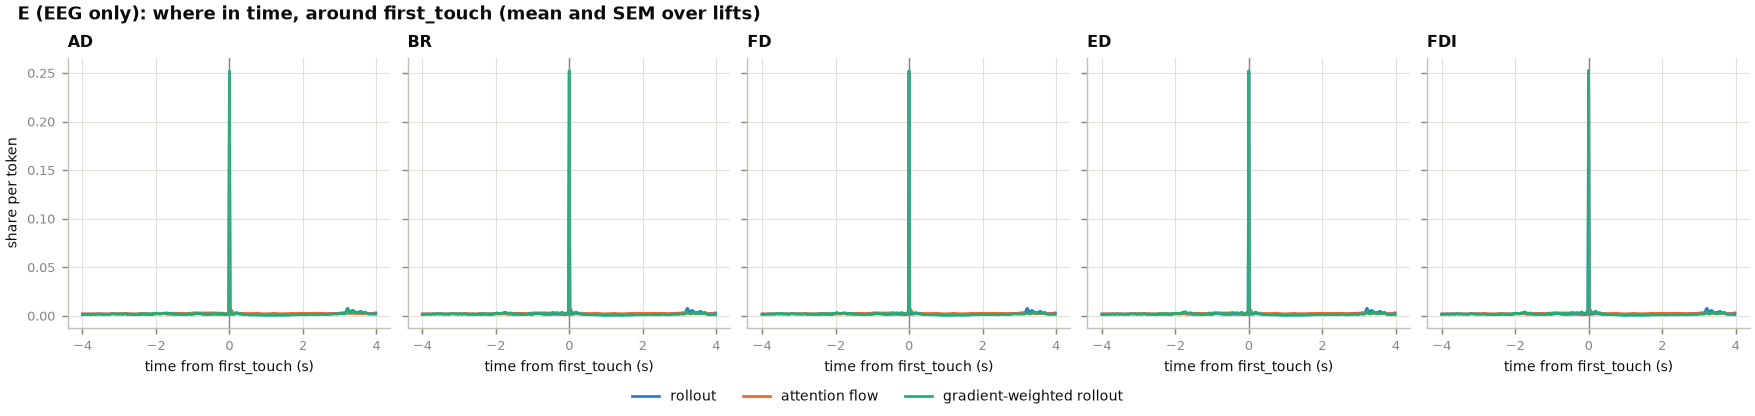

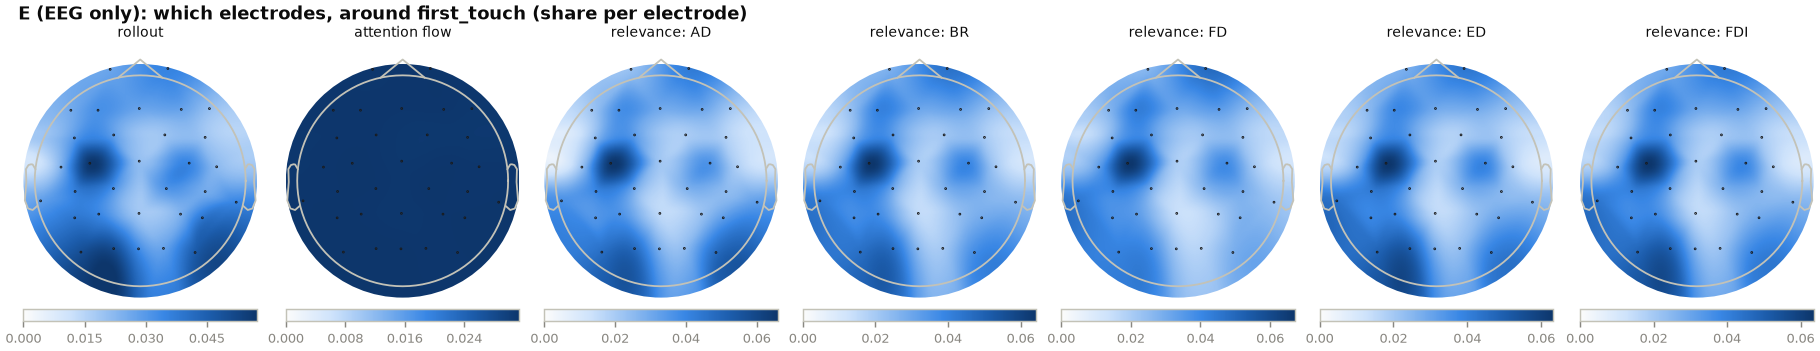

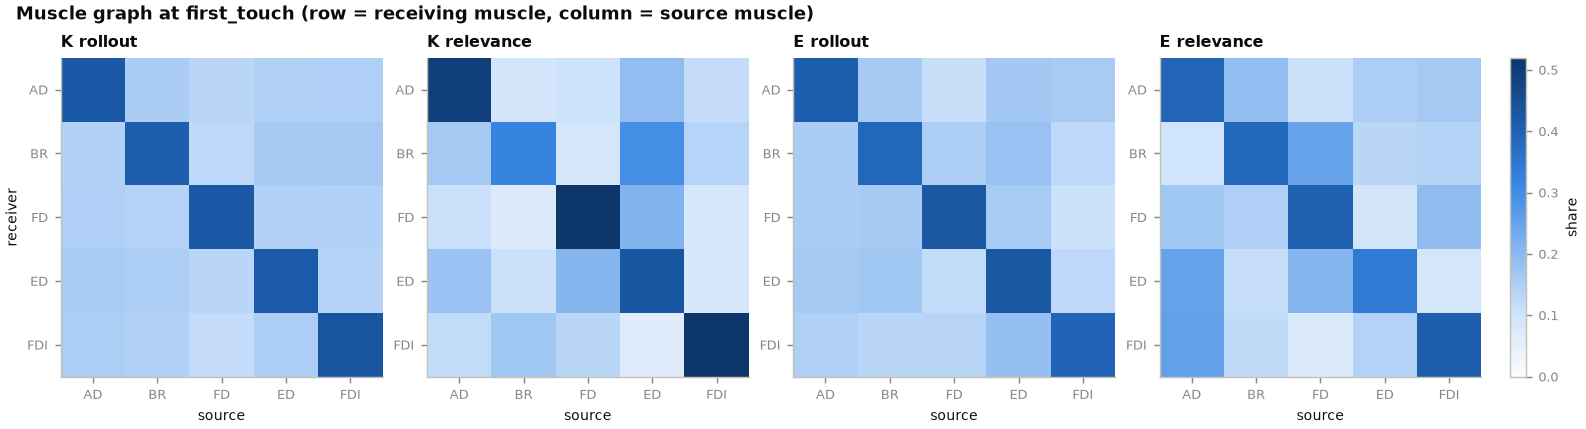

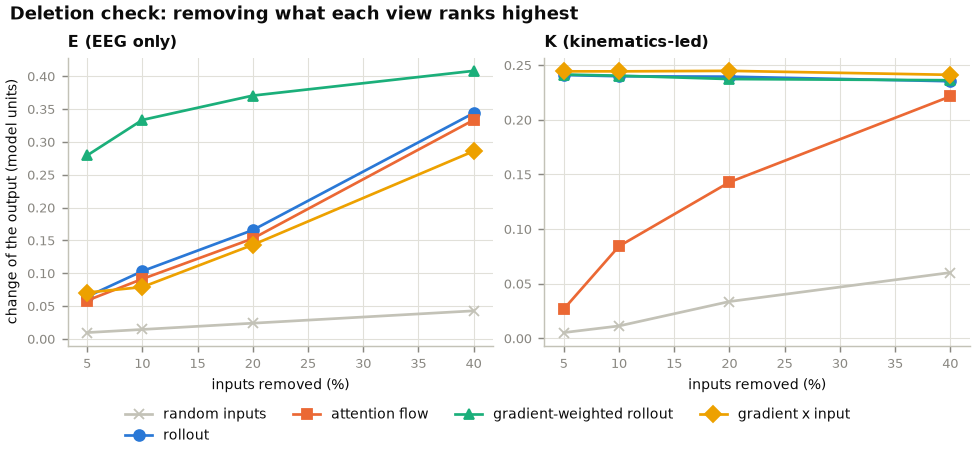


=== P2: 25 figures and 8 tables in outputs\interpretability_v2\P2, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.881 0.851 0.879   0.831 1.059 -0.001
    BR first_touch 60 0.809 0.820 0.810   0.758 1.067  0.001
    FD first_touch 60 0.846 0.836 0.844   0.749 1.130 -0.002
    ED first_touch 60 0.865 0.868 0.863   0.804 1.075 -0.002
   FDI first_touch 60 0.587 0.612 0.587   0.548 1.070  0.000
    AD    lift_off 62 0.947 0.900 0.947   0.894 1.059 -0.000
    BR    lift_off 62 0.973 0.913 0.975   0.912 1.067  0.002
    FD    lift_off 62 0.969 0.896 0.967   0.859 1.128 -0.003
    ED    lift_off 62 0.992 0.925 0.989   0.922 1.075 -0.002
   FDI    lift_off 62 0.941 0.783 0.940   0.880 1.069 -0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

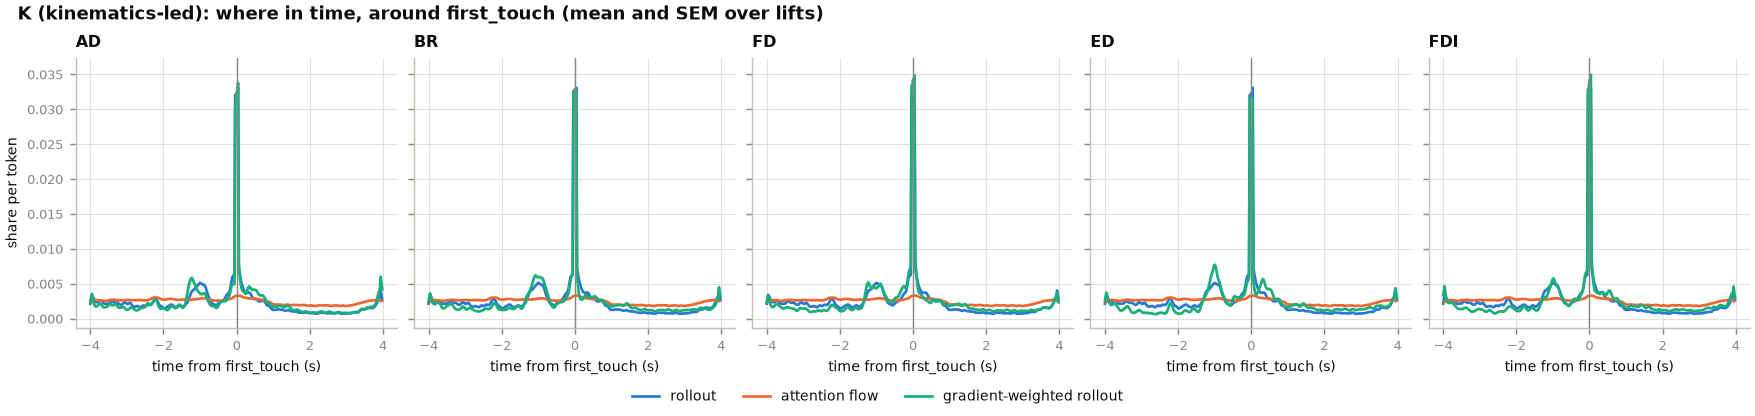

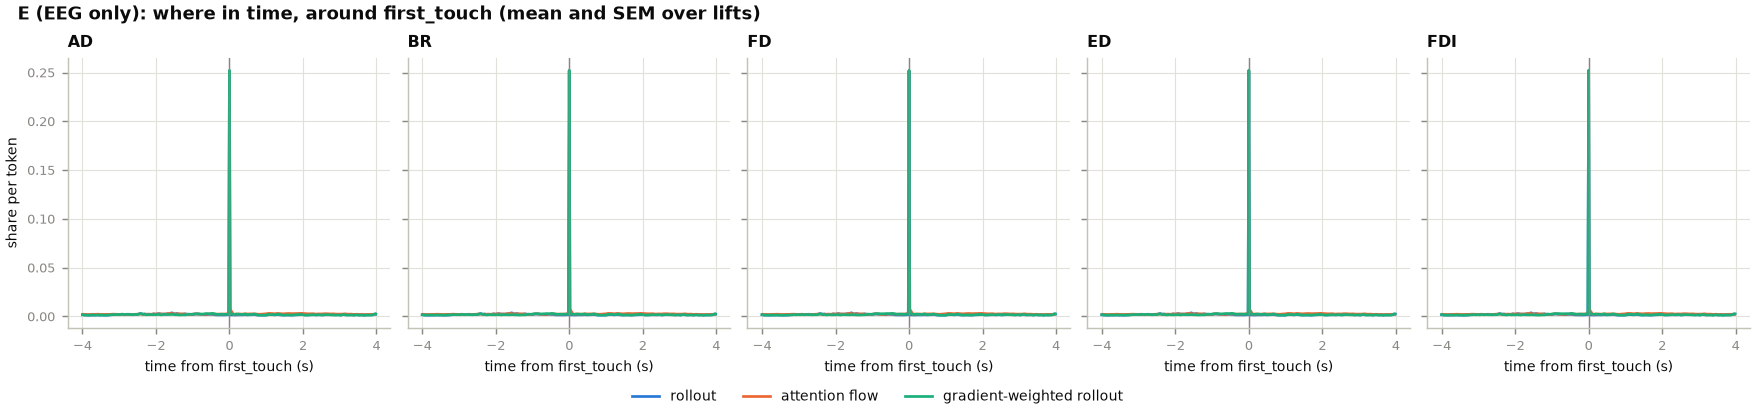

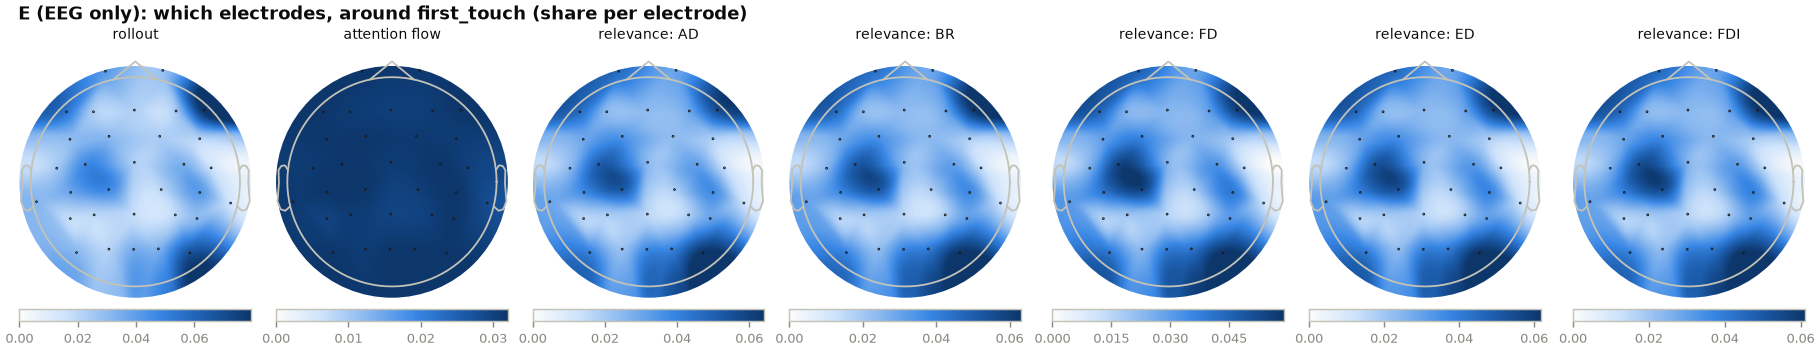

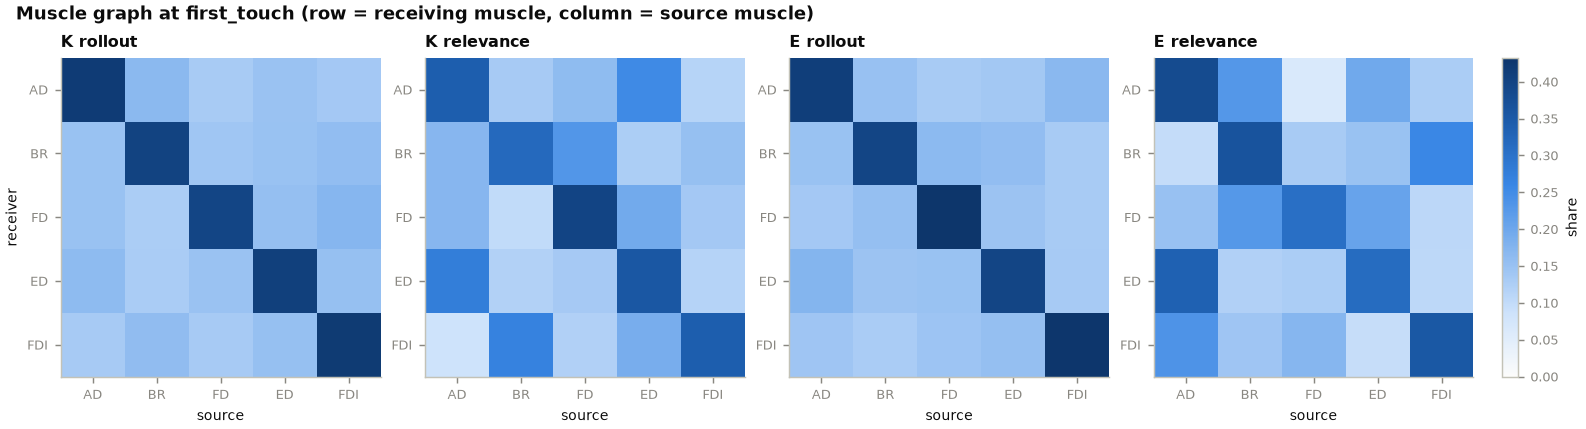

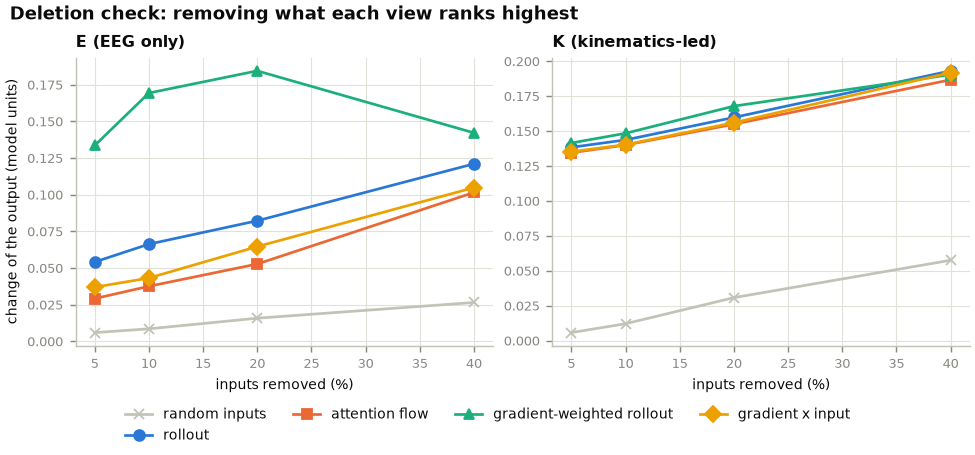


=== P3: 25 figures and 8 tables in outputs\interpretability_v2\P3, 4.1 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.917 0.893 0.917   0.836 1.097  0.000
    BR first_touch 60 0.794 0.814 0.794   0.709 1.120  0.000
    FD first_touch 60 1.099 0.971 1.099   0.934 1.176 -0.001
    ED first_touch 60 0.965 0.865 0.967   0.826 1.168  0.001
   FDI first_touch 60 0.863 0.862 0.864   0.737 1.171  0.000
    AD    lift_off 60 0.996 0.907 0.996   0.908 1.097  0.000
    BR    lift_off 60 1.123 0.833 1.124   1.003 1.120  0.000
    FD    lift_off 60 1.058 0.975 1.058   0.900 1.176 -0.001
    ED    lift_off 60 1.197 0.884 1.198   1.024 1.168  0.001
   FDI    lift_off 60 1.126 0.873 1.127   0.960 1.171  0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

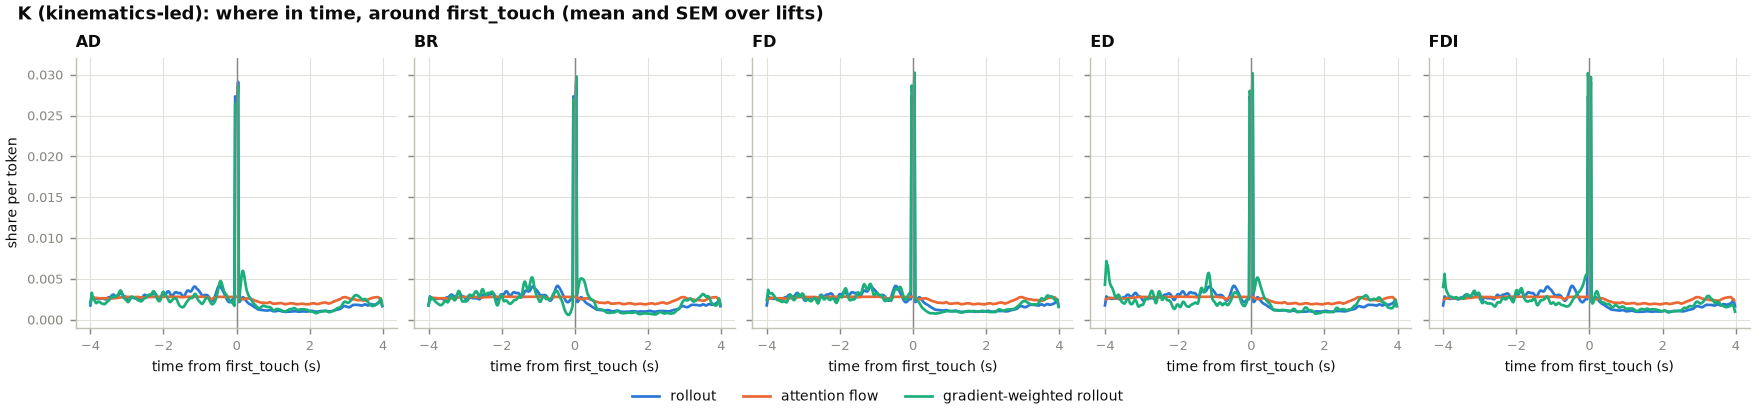

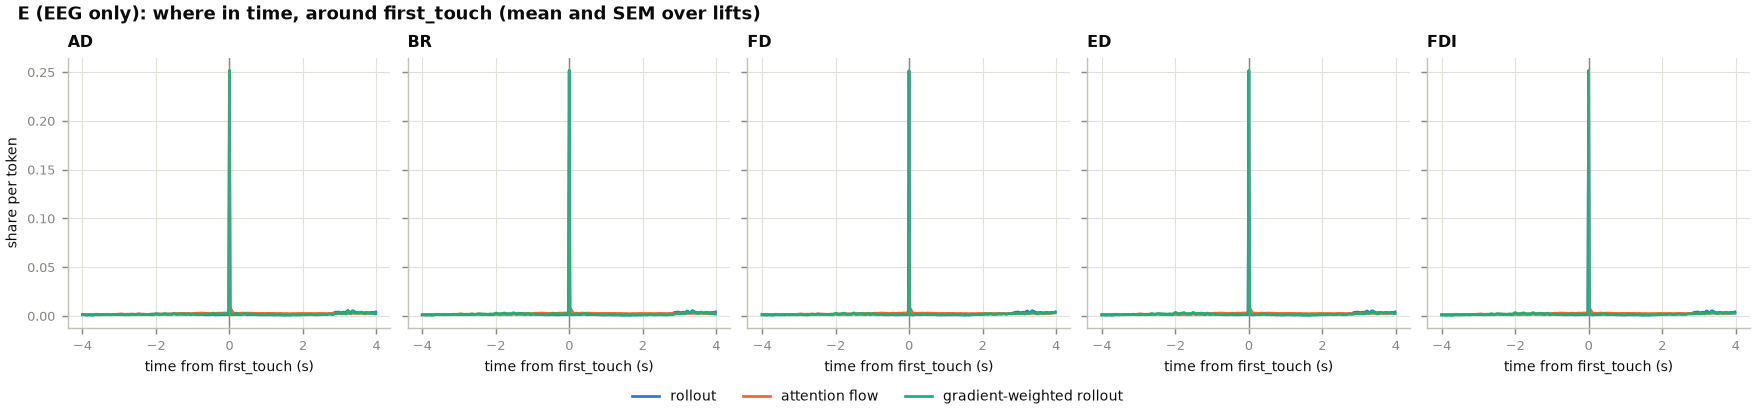

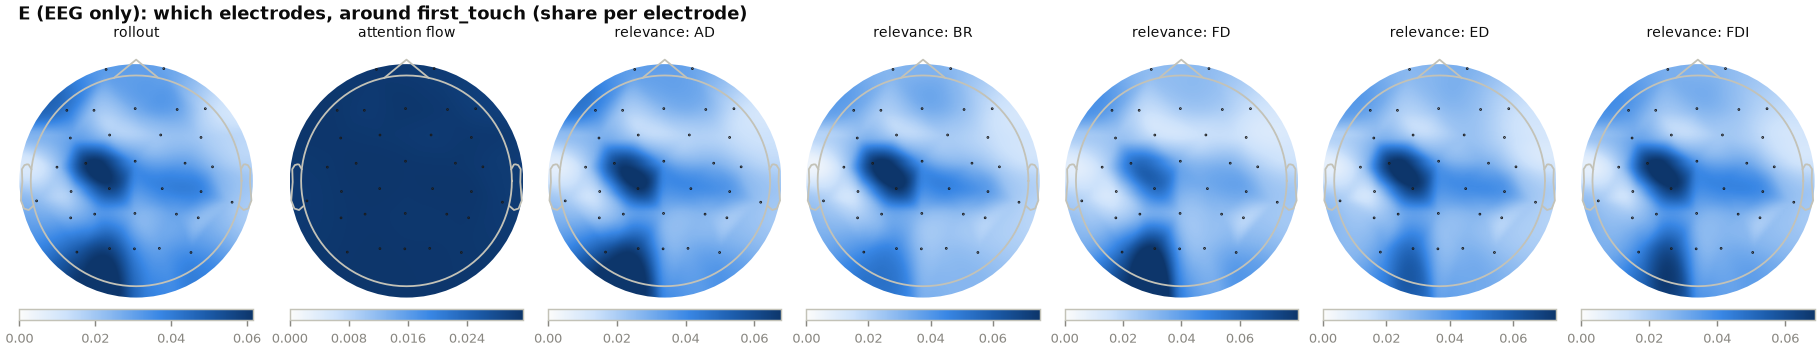

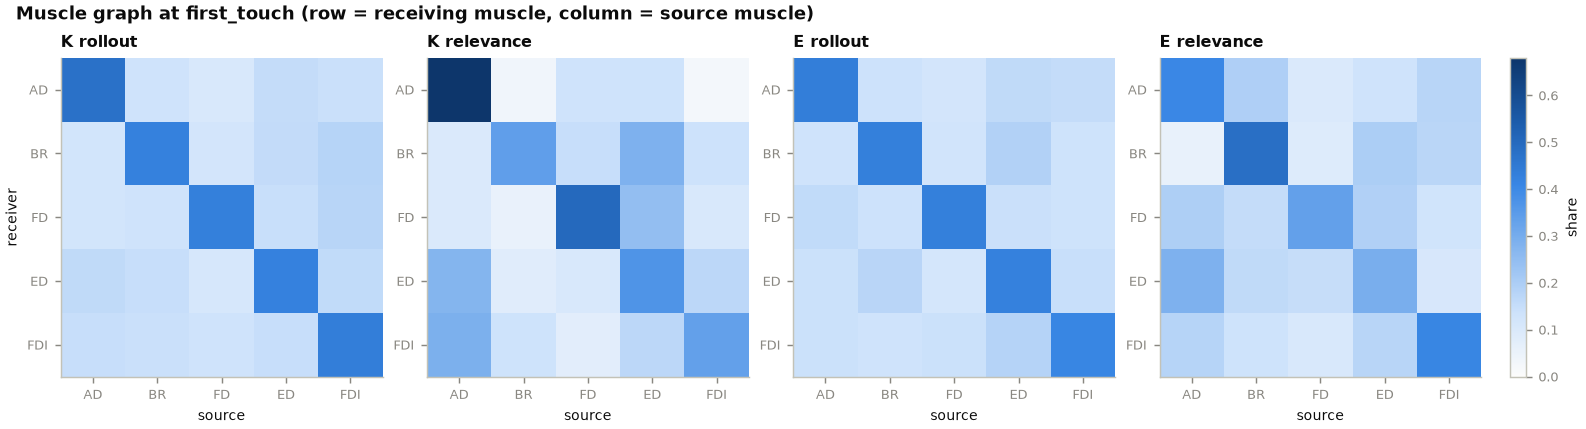

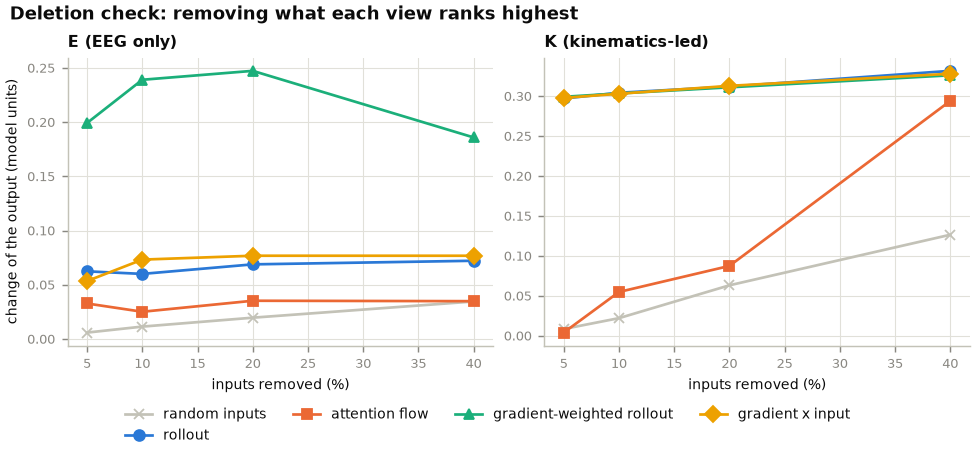


=== P4: 25 figures and 8 tables in outputs\interpretability_v2\P4, 4.1 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.808 0.863 0.807   0.737 1.096 -0.001
    BR first_touch 60 0.935 0.900 0.934   0.838 1.116 -0.001
    FD first_touch 60 0.907 0.879 0.905   0.764 1.188 -0.002
    ED first_touch 60 1.048 0.934 1.048   0.909 1.153 -0.001
   FDI first_touch 60 0.951 0.848 0.950   0.811 1.173 -0.001
    AD    lift_off 60 0.891 0.884 0.892   0.813 1.096  0.001
    BR    lift_off 60 1.020 0.906 1.020   0.914 1.116 -0.000
    FD    lift_off 60 1.054 0.877 1.054   0.888 1.188 -0.000
    ED    lift_off 60 0.985 0.907 0.985   0.855 1.153 -0.000
   FDI    lift_off 60 1.039 0.782 1.039   0.884 1.173  0.001
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

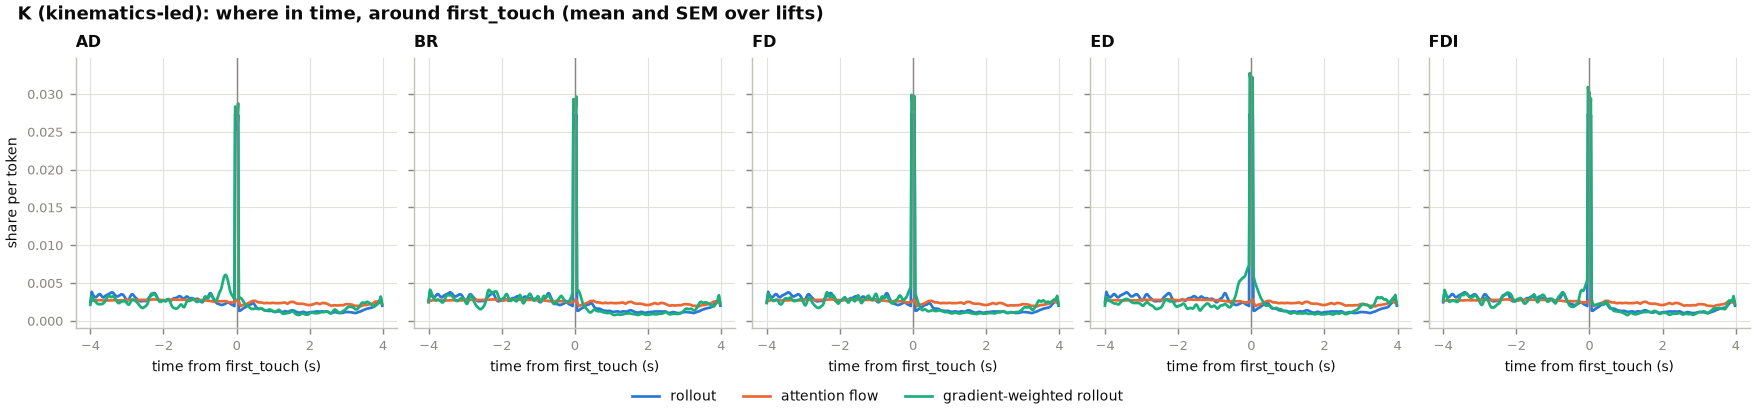

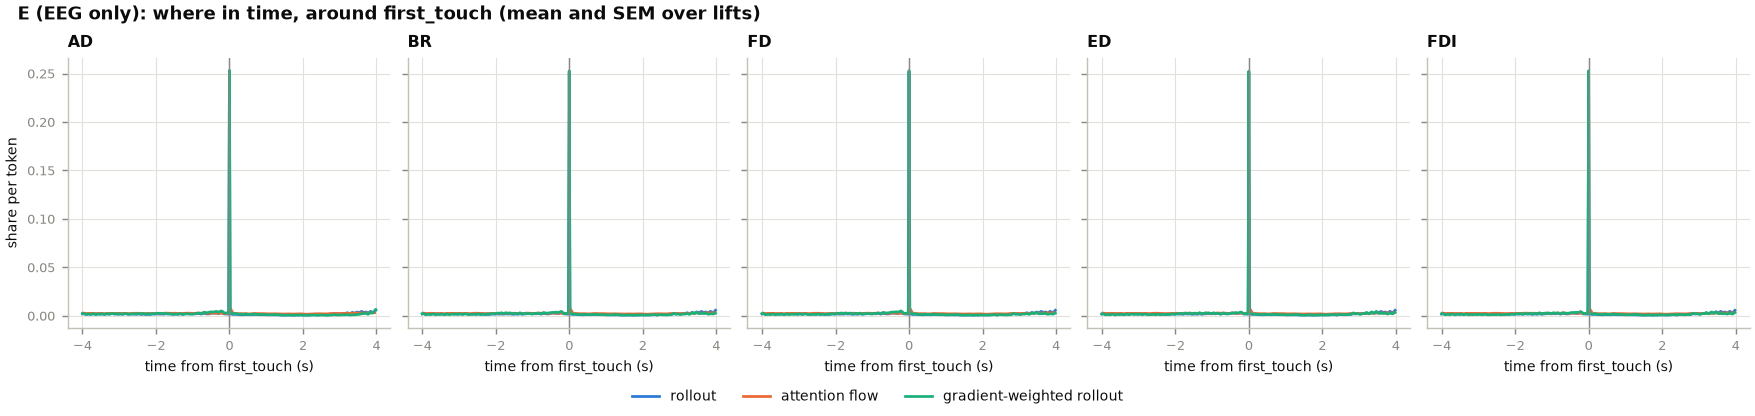

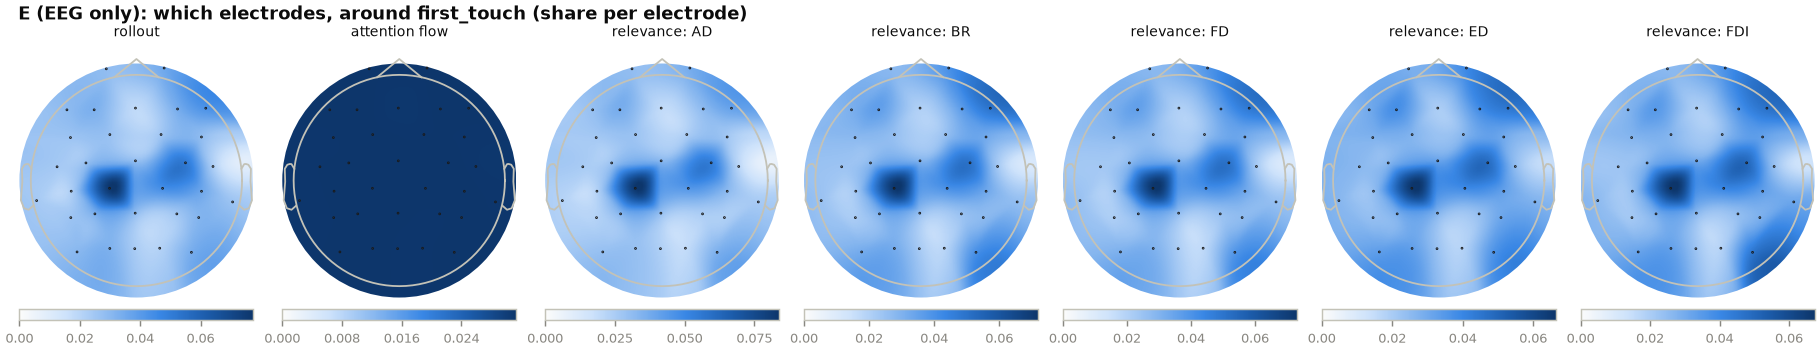

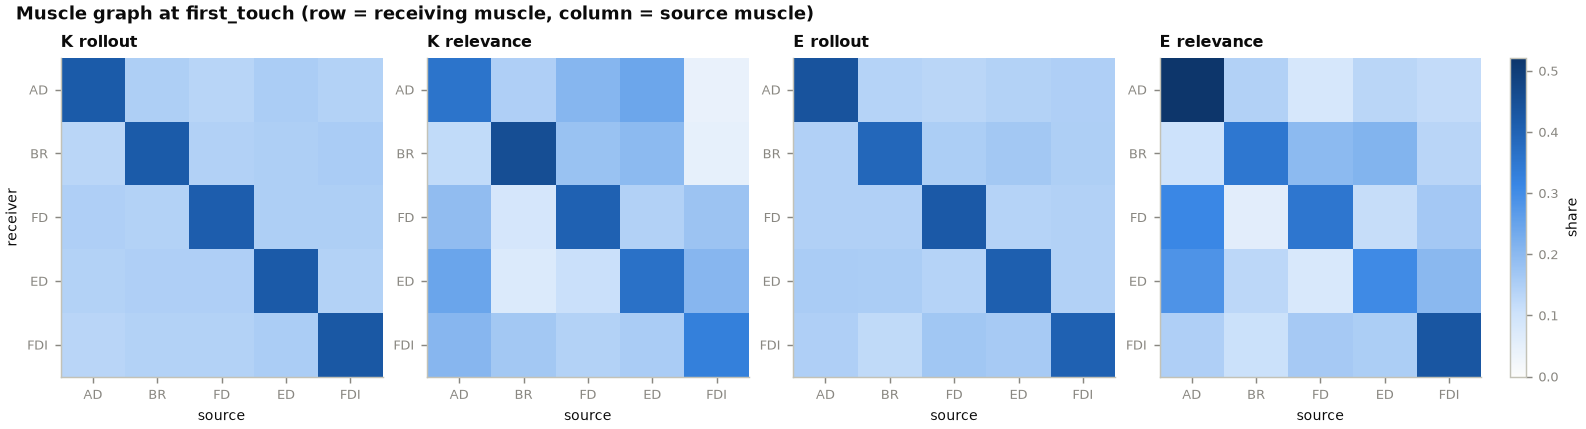

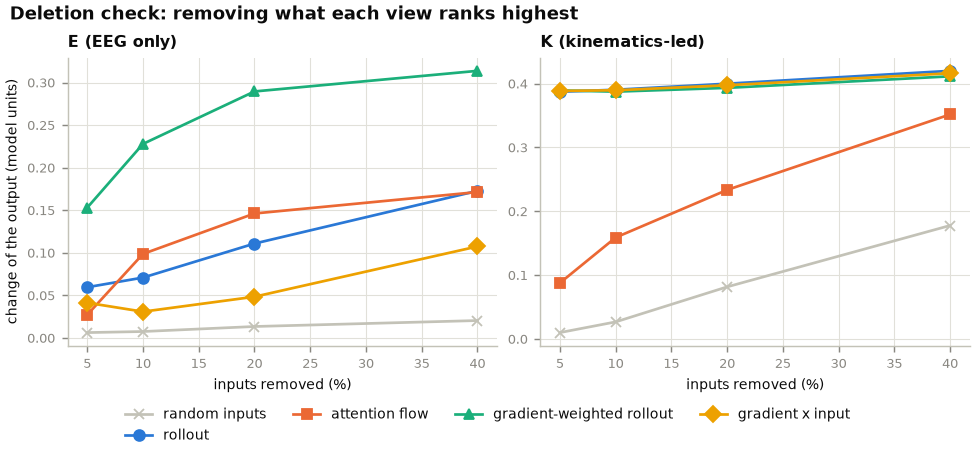


=== P5: 25 figures and 8 tables in outputs\interpretability_v2\P5, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.883 0.898 0.882   0.852 1.036 -0.000
    BR first_touch 60 0.770 0.798 0.772   0.704 1.093  0.002
    FD first_touch 60 0.975 0.916 0.969   0.878 1.110 -0.006
    ED first_touch 60 0.819 0.865 0.816   0.763 1.074 -0.003
   FDI first_touch 60 0.877 0.961 0.878   0.804 1.090  0.002
    AD    lift_off 62 0.972 0.909 0.972   0.937 1.037  0.000
    BR    lift_off 62 0.944 0.843 0.945   0.865 1.092  0.000
    FD    lift_off 62 0.972 0.936 0.969   0.877 1.109 -0.003
    ED    lift_off 62 0.965 0.886 0.965   0.898 1.074  0.000
   FDI    lift_off 62 1.000 0.945 1.001   0.917 1.089  0.001
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

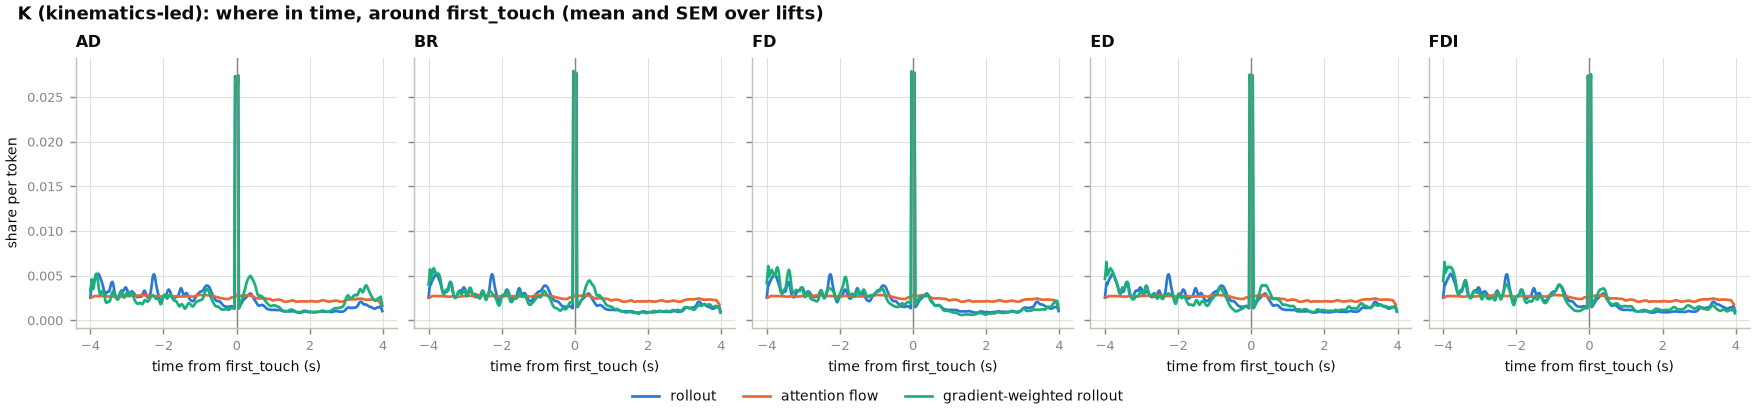

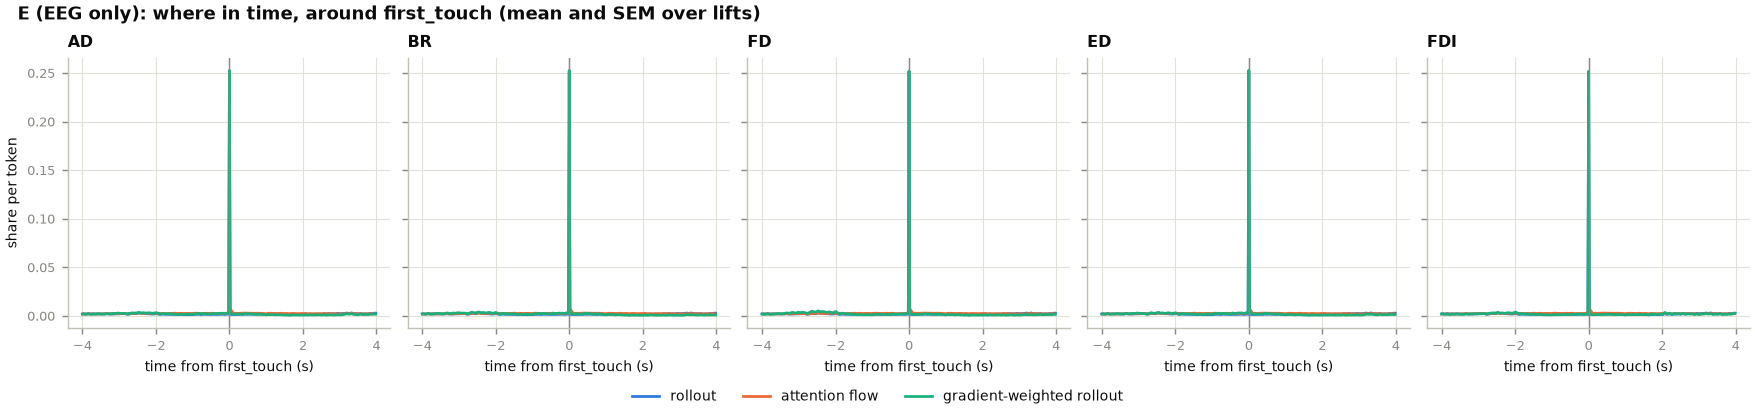

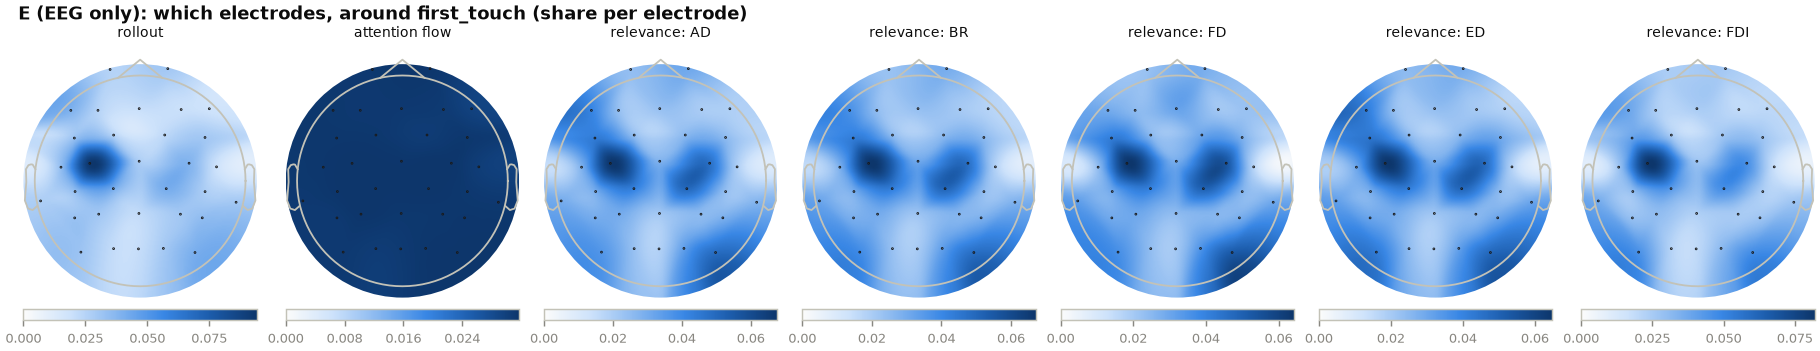

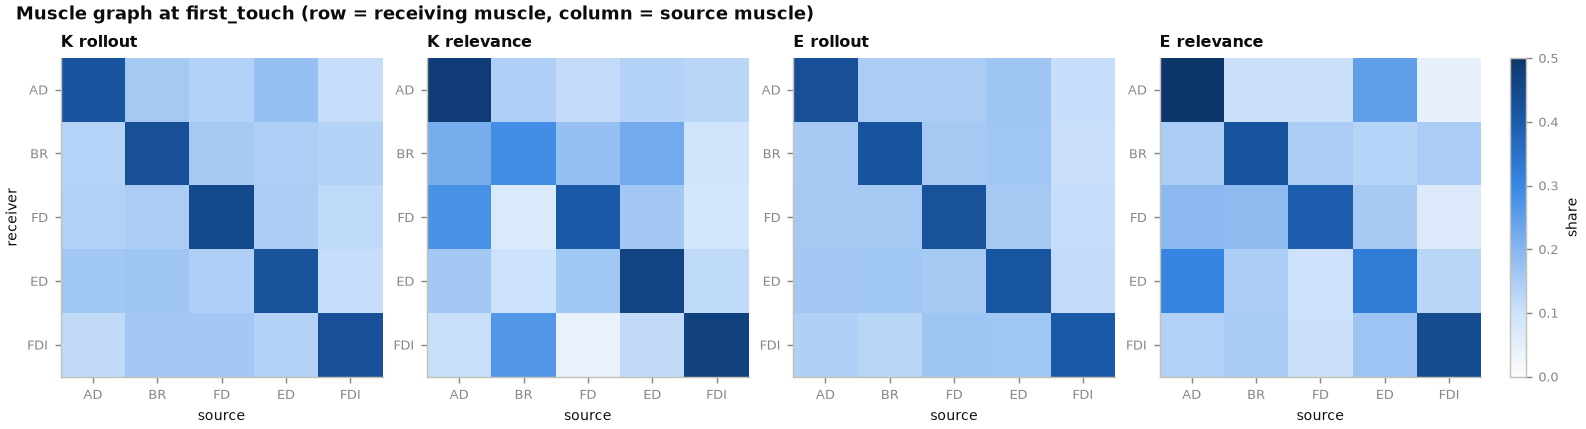

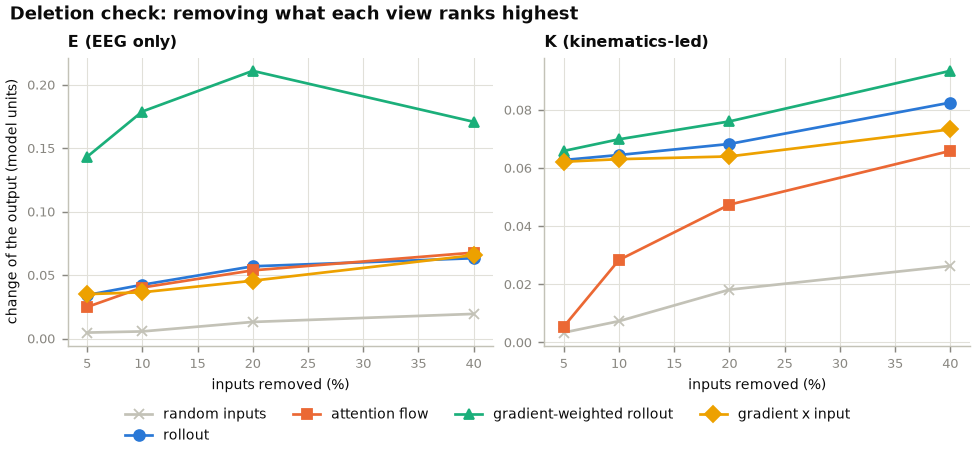


=== P6: 25 figures and 8 tables in outputs\interpretability_v2\P6, 4.1 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.895 0.777 0.896   0.828 1.081  0.000
    BR first_touch 60 0.818 0.776 0.818   0.750 1.091 -0.000
    FD first_touch 60 0.979 0.899 0.980   0.859 1.139  0.001
    ED first_touch 60 0.942 0.784 0.942   0.818 1.151  0.000
   FDI first_touch 60 0.549 0.681 0.548   0.484 1.133 -0.000
    AD    lift_off 62 0.959 0.787 0.959   0.888 1.080  0.000
    BR    lift_off 62 0.980 0.806 0.978   0.900 1.089 -0.001
    FD    lift_off 62 0.960 0.907 0.961   0.845 1.137  0.000
    ED    lift_off 62 0.966 0.797 0.967   0.842 1.148  0.001
   FDI    lift_off 62 0.990 0.728 0.990   0.876 1.130  0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

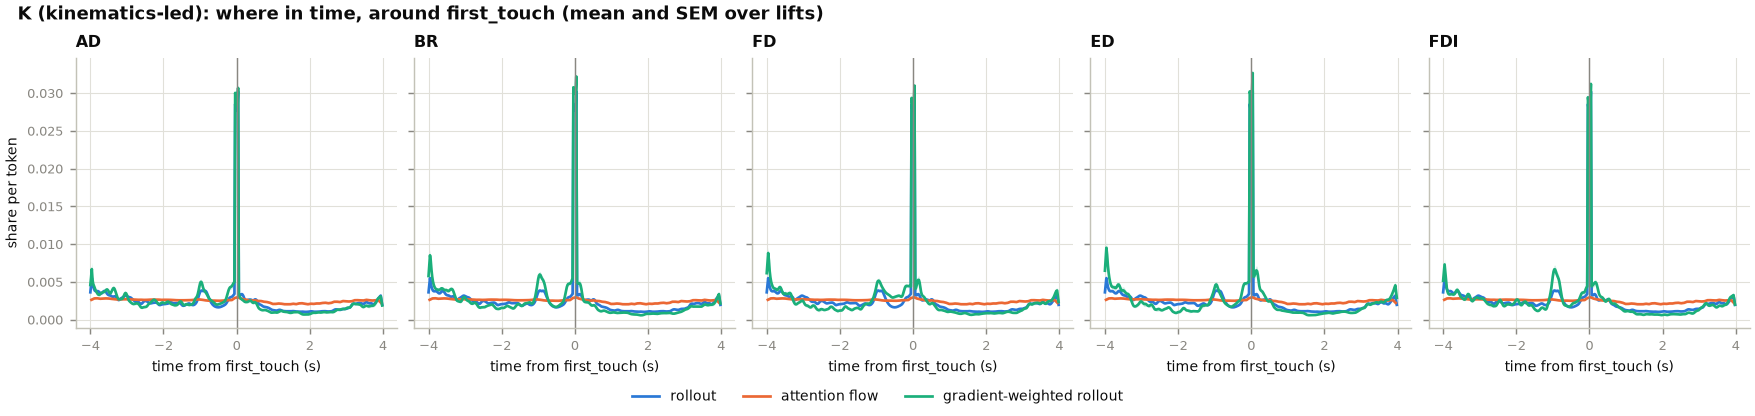

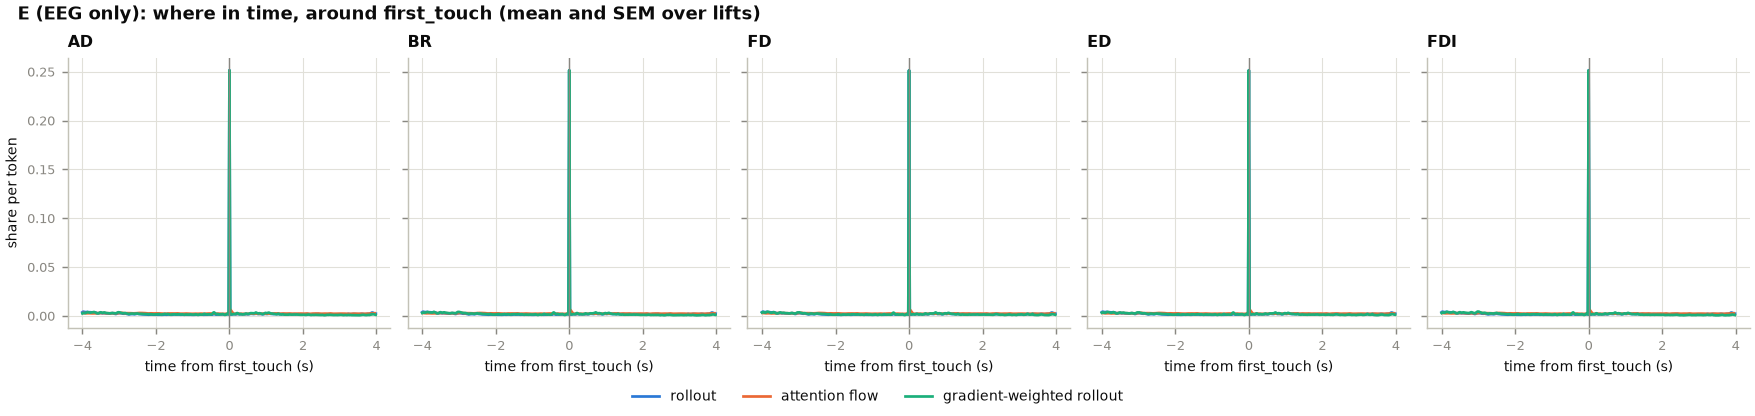

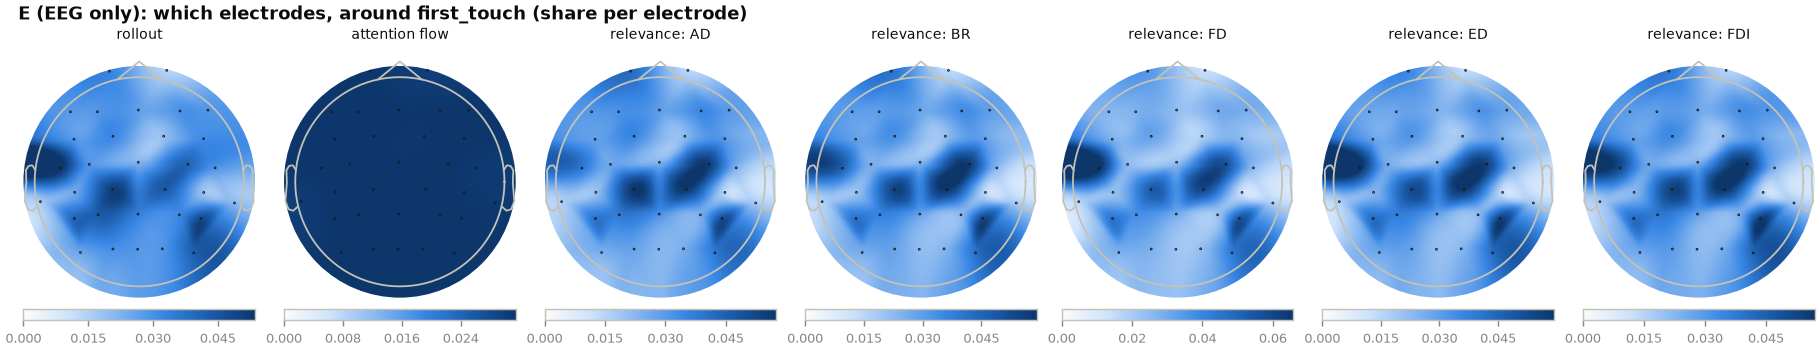

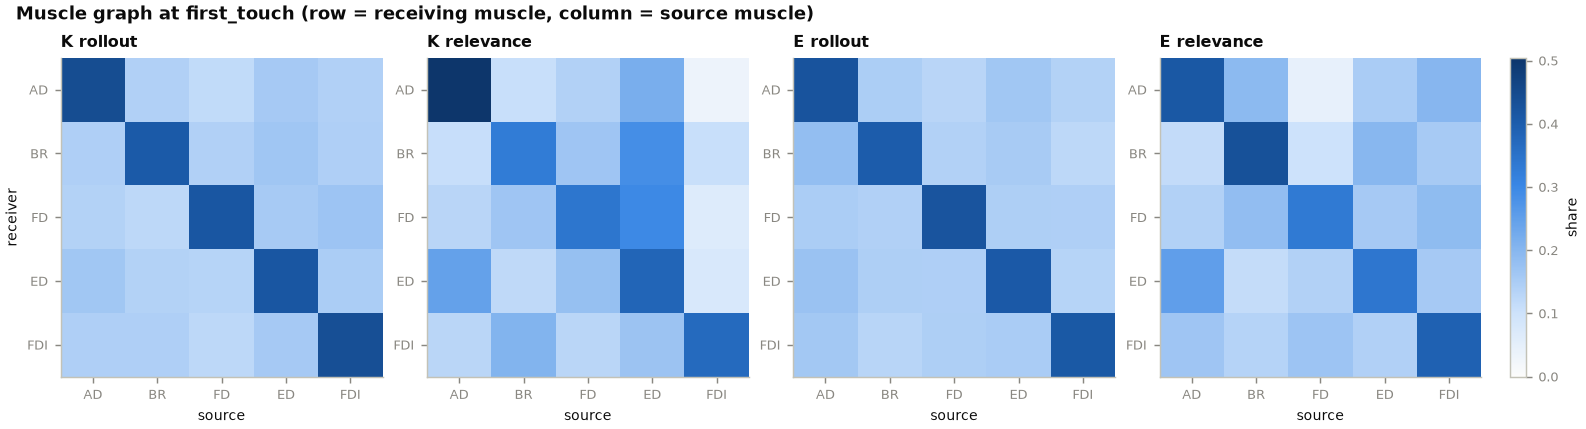

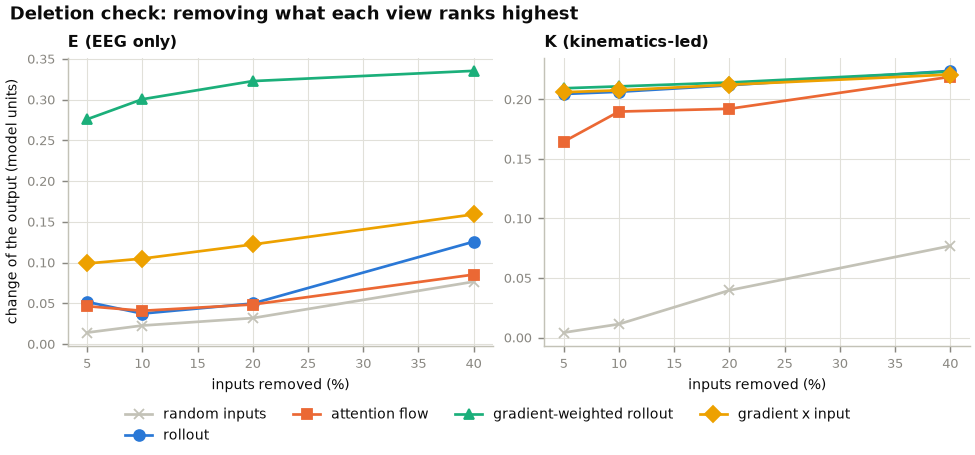


=== P7: 25 figures and 8 tables in outputs\interpretability_v2\P7, 4.1 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 61 0.854 0.851 0.854   0.769 1.111   -0.0
    BR first_touch 61 0.651 0.748 0.651   0.587 1.109   -0.0
    FD first_touch 61 0.747 0.832 0.747   0.641 1.165   -0.0
    ED first_touch 61 0.841 0.907 0.841   0.738 1.140    0.0
   FDI first_touch 61 0.337 0.520 0.337   0.285 1.184   -0.0
    AD    lift_off 62 0.919 0.898 0.920   0.828 1.110    0.0
    BR    lift_off 62 0.921 0.855 0.921   0.832 1.108    0.0
    FD    lift_off 62 0.980 0.915 0.981   0.843 1.163    0.0
    ED    lift_off 62 0.944 0.926 0.944   0.829 1.139    0.0
   FDI    lift_off 62 0.884 0.718 0.884   0.747 1.181   -0.0
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

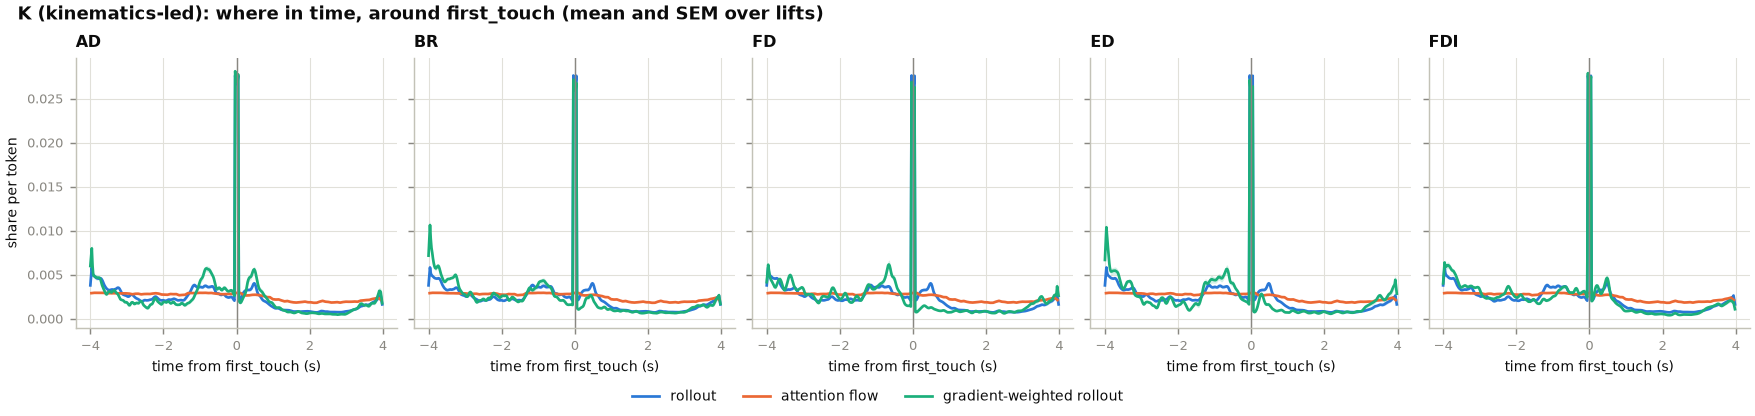

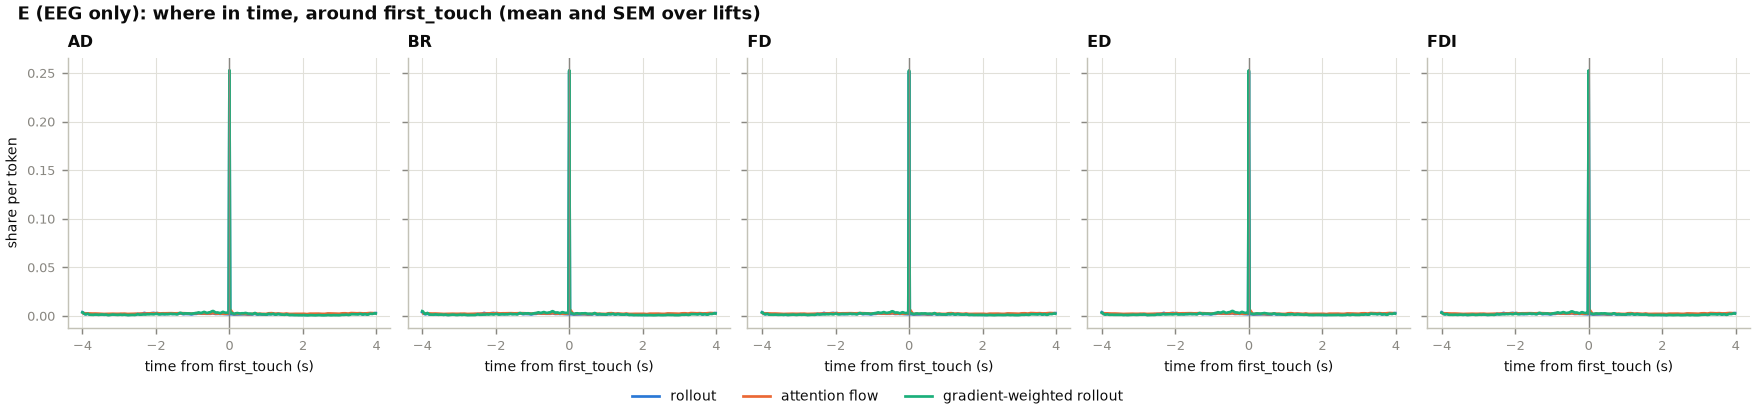

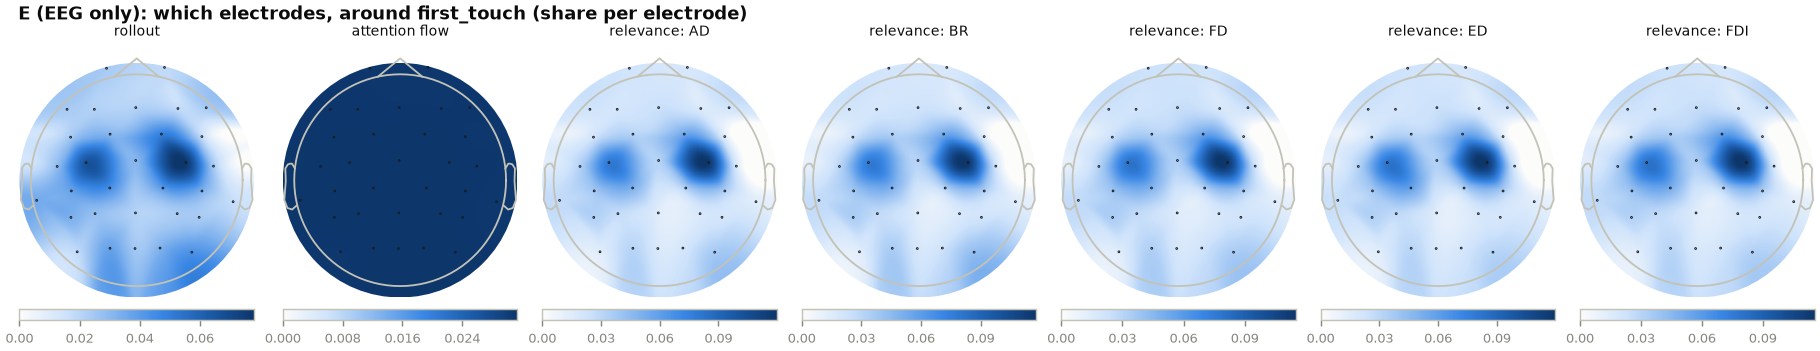

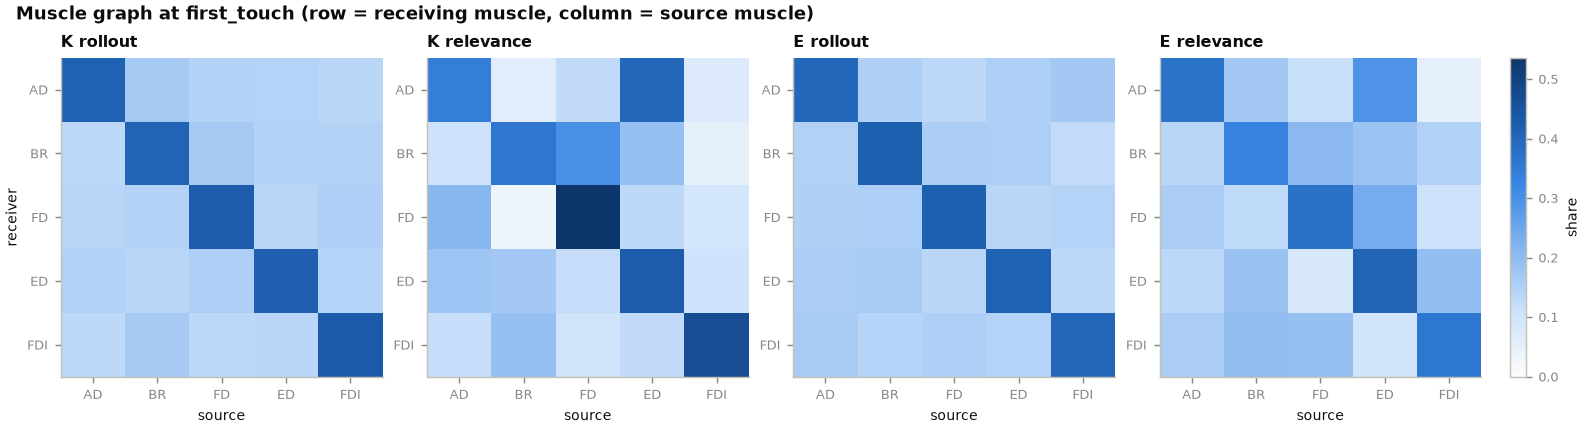

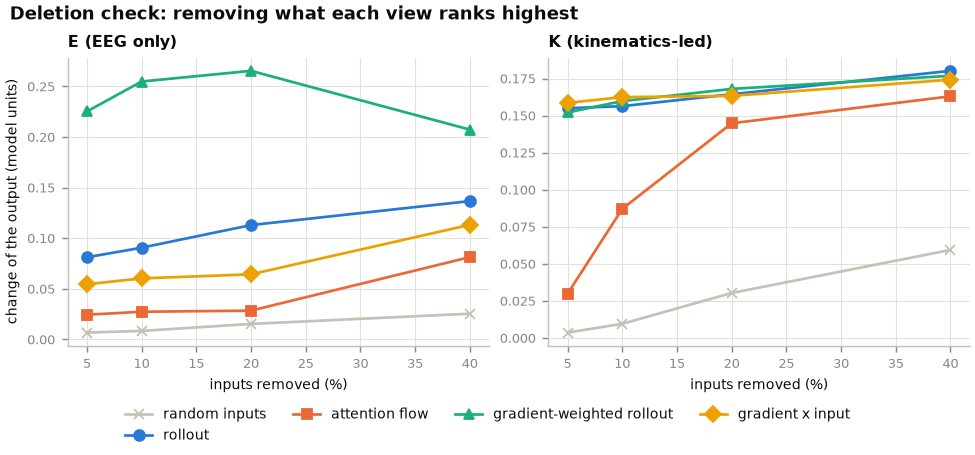


=== P8: 25 figures and 8 tables in outputs\interpretability_v2\P8, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.861 0.805 0.861   0.796 1.081  0.000
    BR first_touch 60 0.714 0.731 0.713   0.652 1.095 -0.001
    FD first_touch 60 0.971 0.929 0.971   0.825 1.176 -0.000
    ED first_touch 60 0.810 0.779 0.809   0.699 1.158 -0.001
   FDI first_touch 60 0.454 0.594 0.454   0.393 1.157 -0.000
    AD    lift_off 61 0.922 0.859 0.921   0.853 1.080 -0.000
    BR    lift_off 61 0.983 0.810 0.982   0.898 1.094 -0.001
    FD    lift_off 61 0.944 0.940 0.944   0.803 1.175  0.001
    ED    lift_off 61 1.053 0.859 1.054   0.911 1.156  0.001
   FDI    lift_off 61 1.082 0.680 1.082   0.936 1.155 -0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

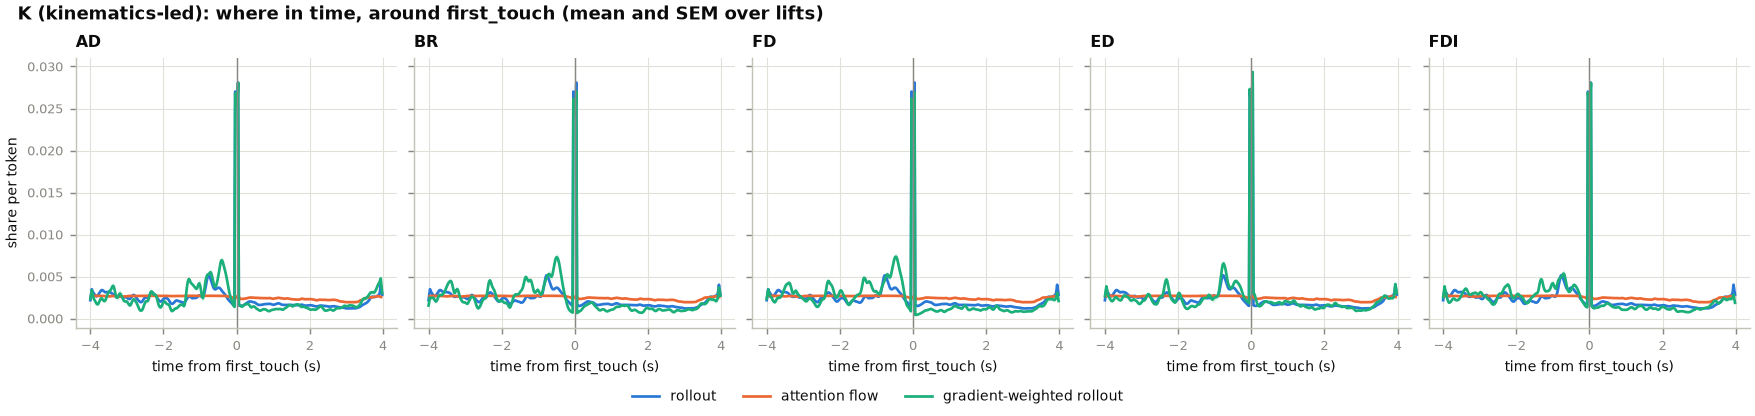

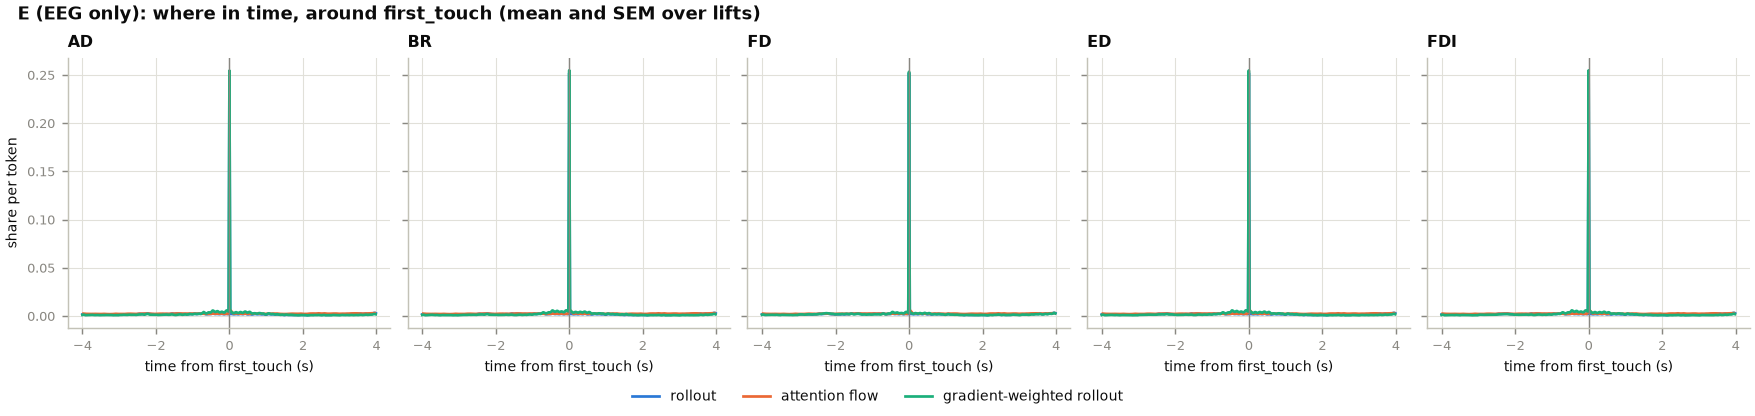

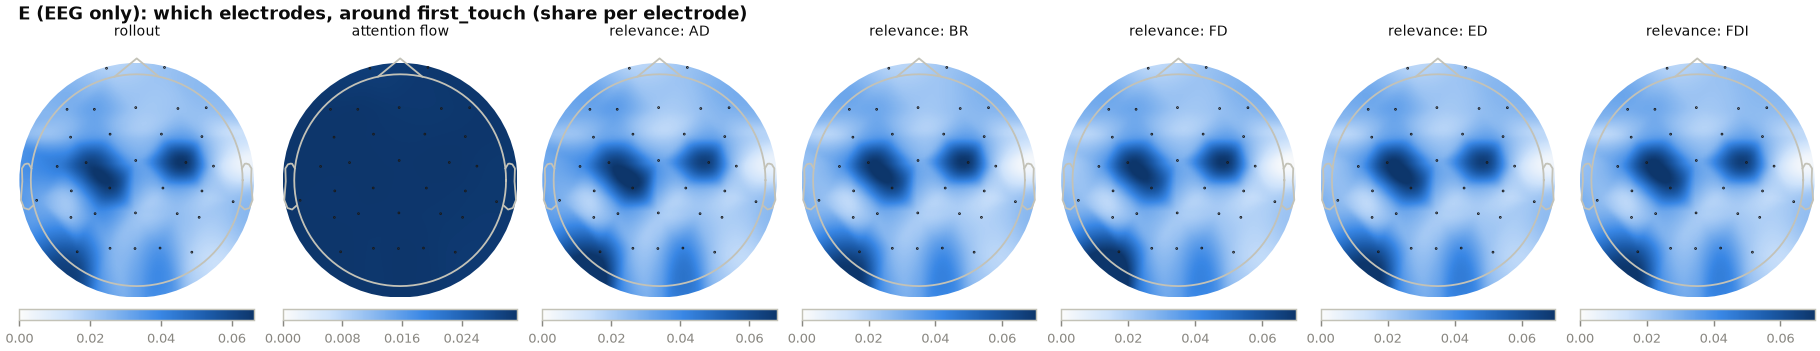

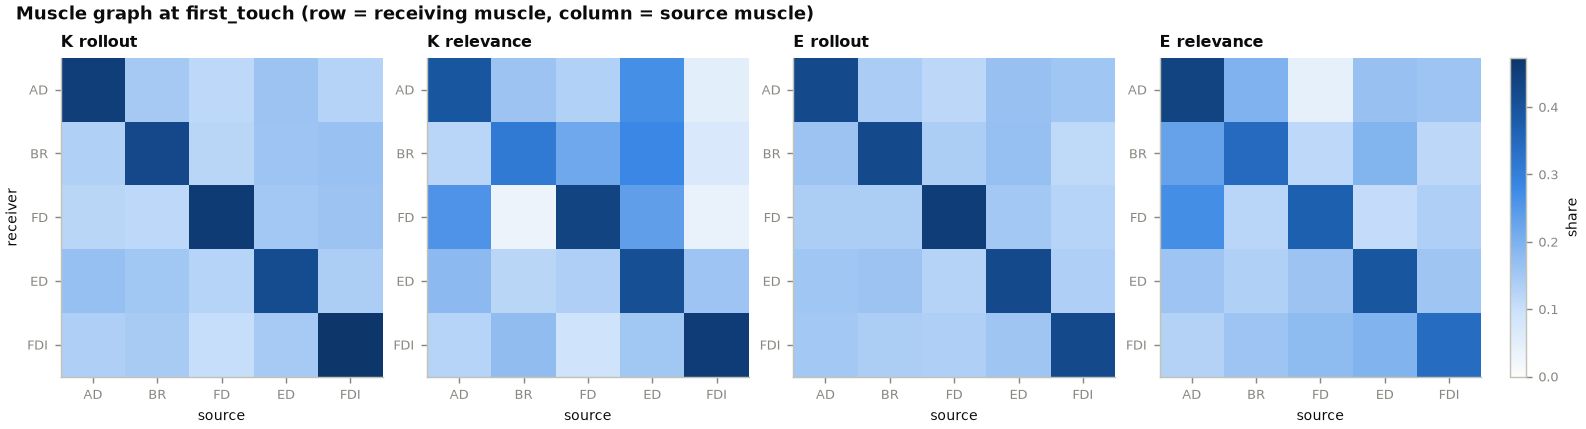

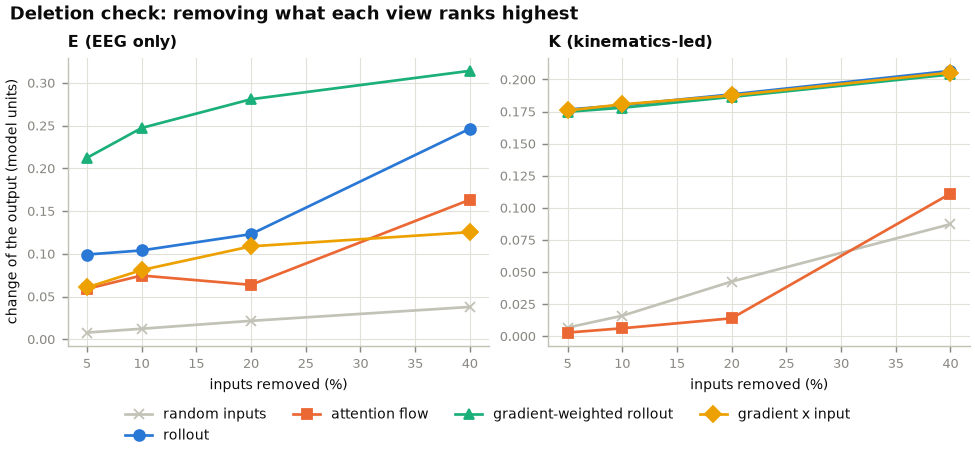


=== P9: 25 figures and 8 tables in outputs\interpretability_v2\P9, 4.1 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.842 0.740 0.842   0.783 1.076  0.000
    BR first_touch 60 0.783 0.779 0.782   0.707 1.107 -0.001
    FD first_touch 60 0.734 0.787 0.734   0.628 1.169 -0.000
    ED first_touch 60 0.895 0.782 0.895   0.783 1.143 -0.000
   FDI first_touch 60 0.338 0.508 0.338   0.287 1.180  0.000
    AD    lift_off 61 0.950 0.788 0.950   0.883 1.075  0.000
    BR    lift_off 61 1.011 0.826 1.012   0.914 1.106  0.001
    FD    lift_off 61 0.979 0.833 0.981   0.838 1.167  0.001
    ED    lift_off 61 1.025 0.823 1.027   0.897 1.142  0.002
   FDI    lift_off 61 0.753 0.575 0.753   0.639 1.178  0.001
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                       

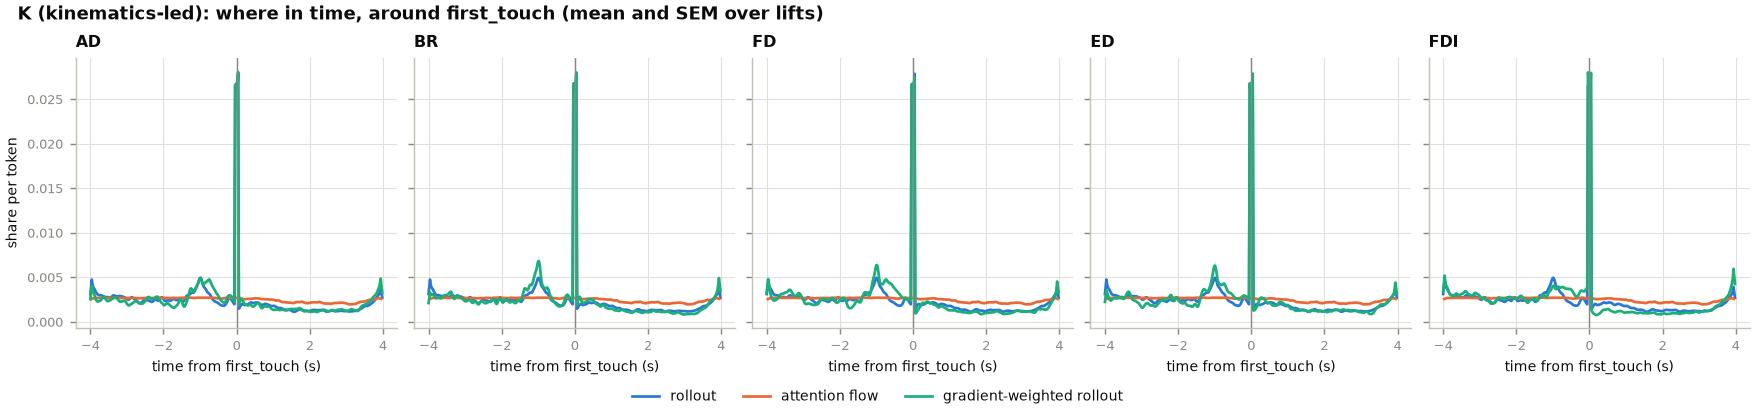

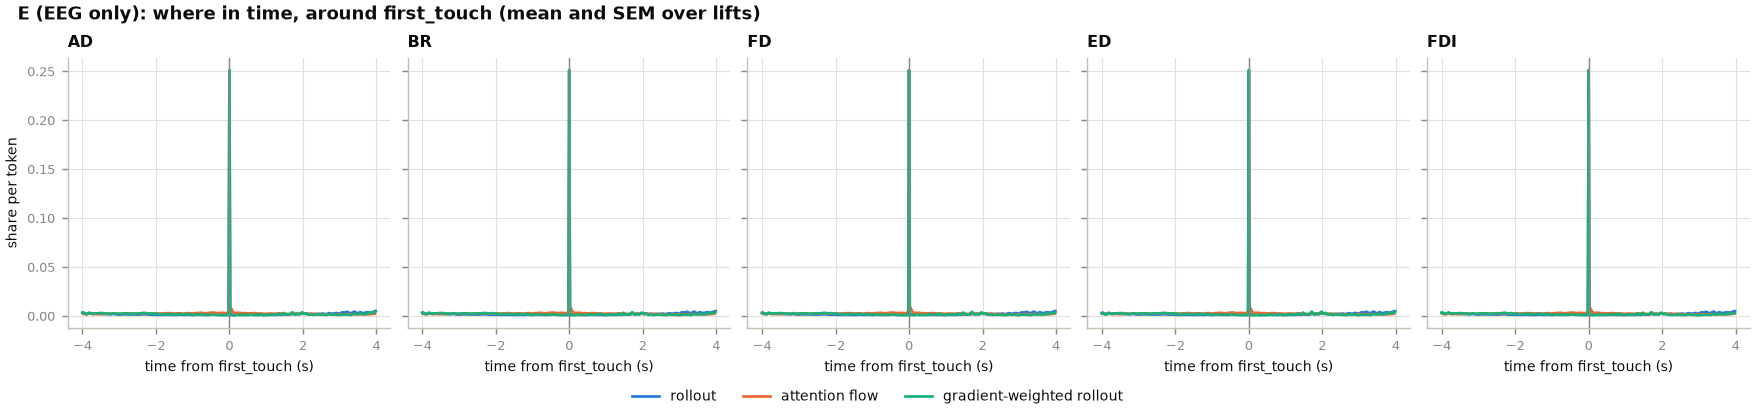

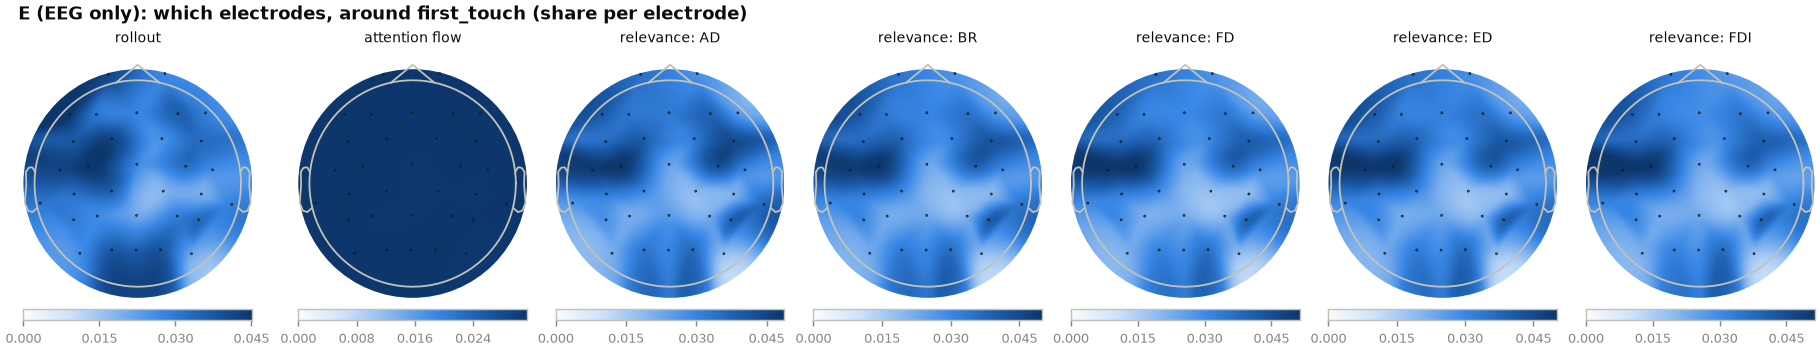

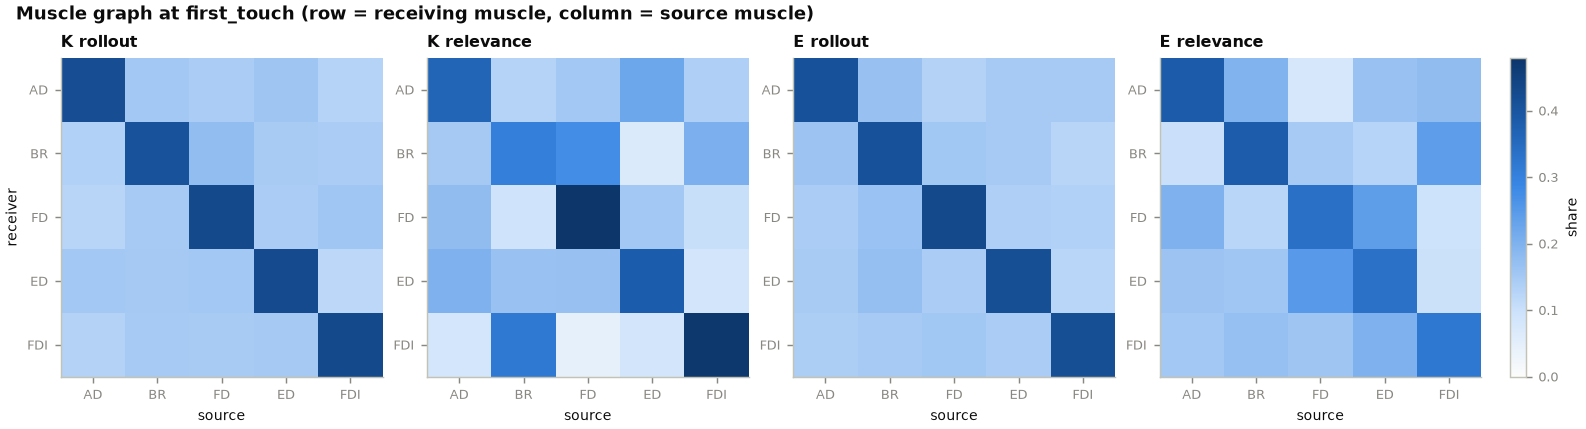

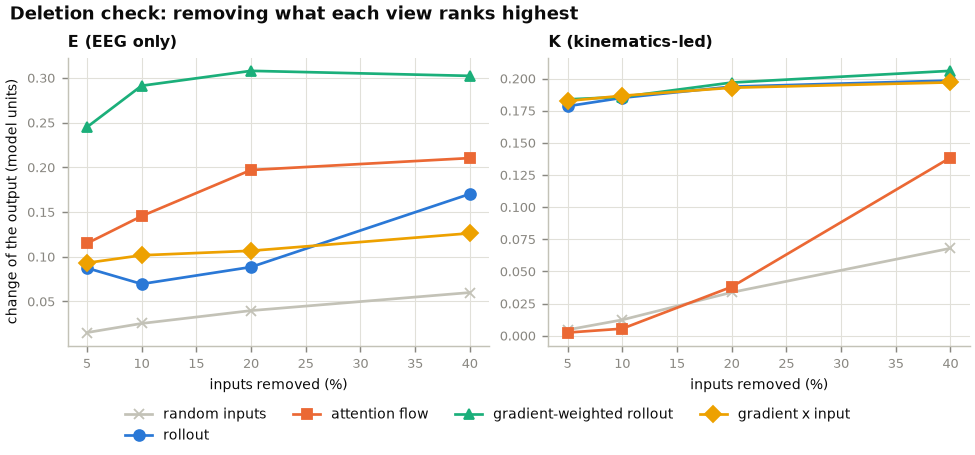


=== P10: 25 figures and 8 tables in outputs\interpretability_v2\P10, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 60 0.860 0.878 0.860   0.781 1.101  0.000
    BR first_touch 60 0.699 0.740 0.698   0.641 1.090 -0.000
    FD first_touch 60 0.796 0.755 0.795   0.632 1.259 -0.001
    ED first_touch 60 0.902 0.842 0.901   0.825 1.094 -0.001
   FDI first_touch 60 0.684 0.704 0.684   0.620 1.103 -0.000
    AD    lift_off 61 0.931 0.908 0.931   0.846 1.100  0.000
    BR    lift_off 61 0.899 0.807 0.899   0.826 1.089 -0.000
    FD    lift_off 61 0.804 0.779 0.804   0.640 1.256 -0.000
    ED    lift_off 61 0.923 0.880 0.922   0.844 1.093 -0.001
   FDI    lift_off 61 0.950 0.781 0.950   0.862 1.102  0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                     

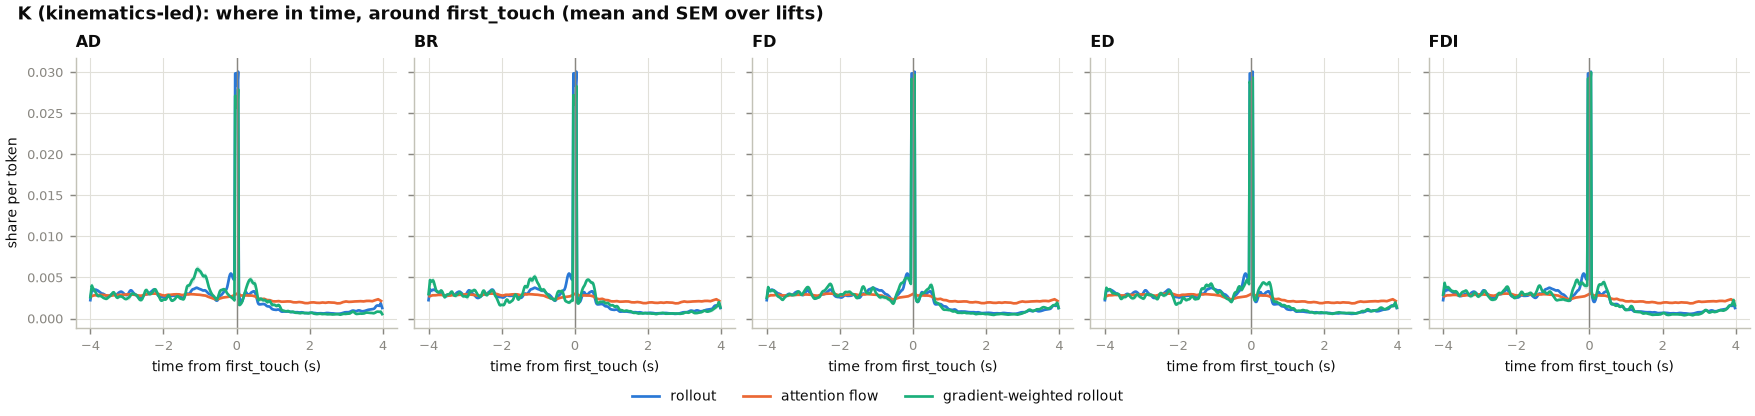

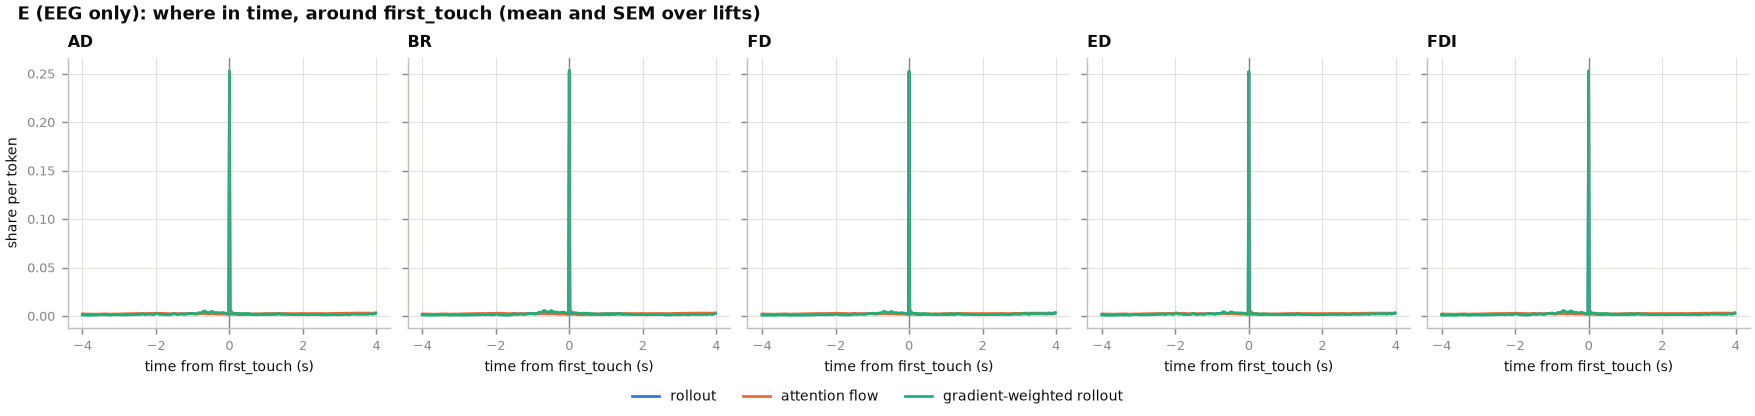

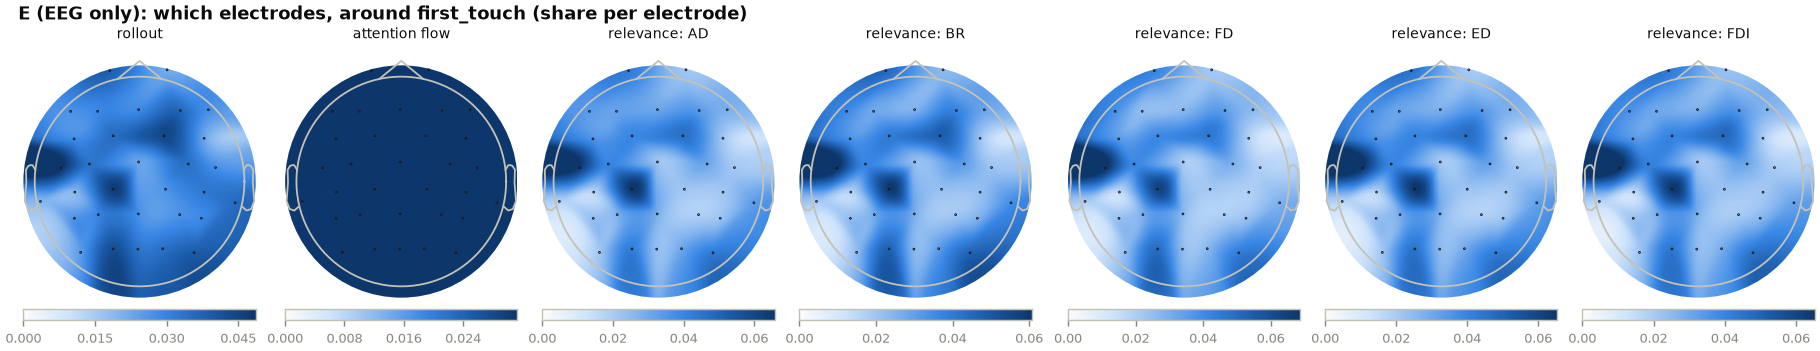

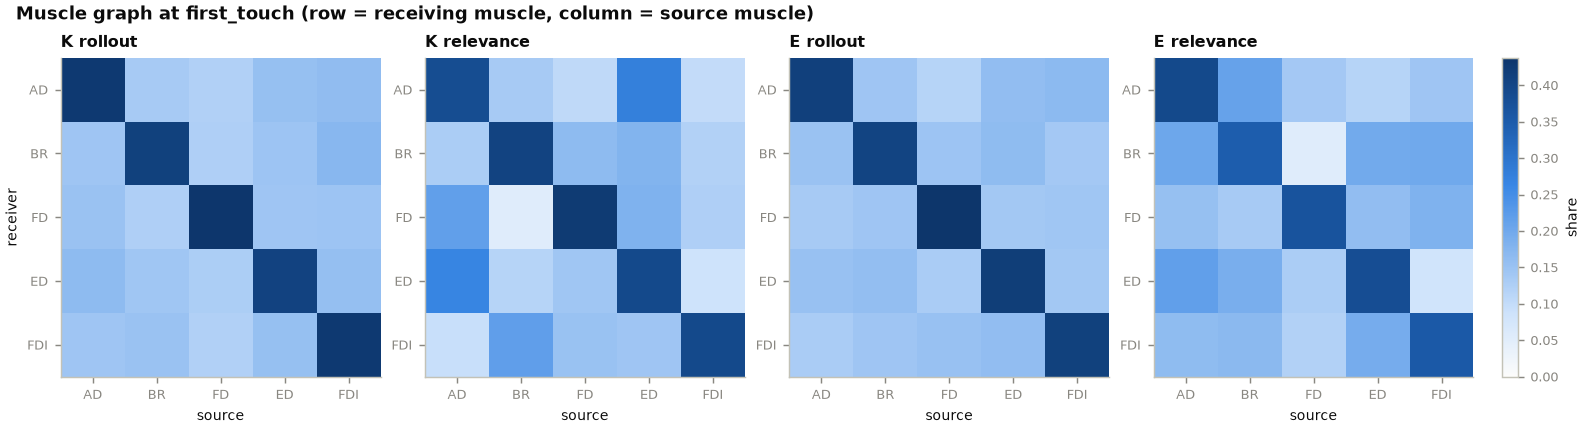

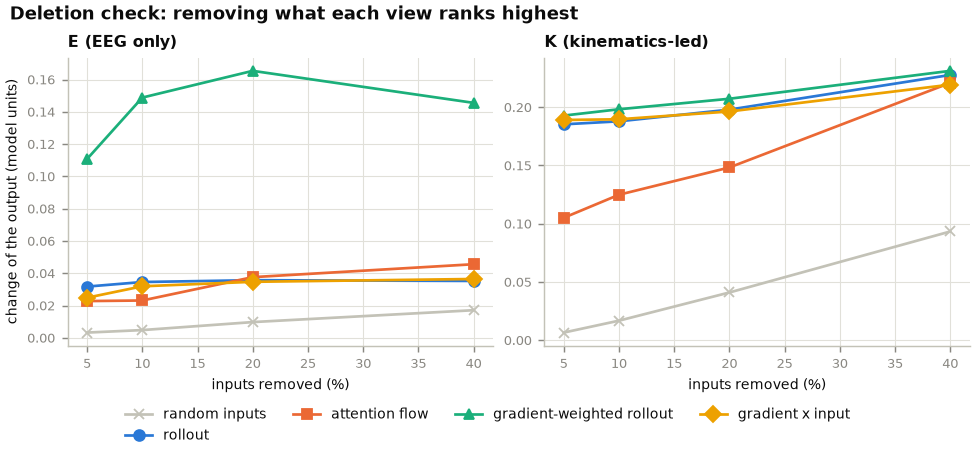


=== P11: 25 figures and 8 tables in outputs\interpretability_v2\P11, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 62 0.870 0.749 0.871   0.808 1.076  0.001
    BR first_touch 62 0.858 0.795 0.858   0.776 1.105 -0.001
    FD first_touch 62 0.960 0.862 0.962   0.851 1.129  0.002
    ED first_touch 62 0.946 0.742 0.947   0.841 1.125  0.001
   FDI first_touch 62 0.752 0.748 0.752   0.658 1.142 -0.000
    AD    lift_off 62 0.929 0.783 0.929   0.864 1.076 -0.000
    BR    lift_off 62 0.978 0.816 0.976   0.885 1.105 -0.002
    FD    lift_off 62 0.964 0.868 0.964   0.854 1.129  0.000
    ED    lift_off 62 0.945 0.764 0.944   0.840 1.125 -0.001
   FDI    lift_off 62 0.987 0.763 0.987   0.865 1.142 -0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                     

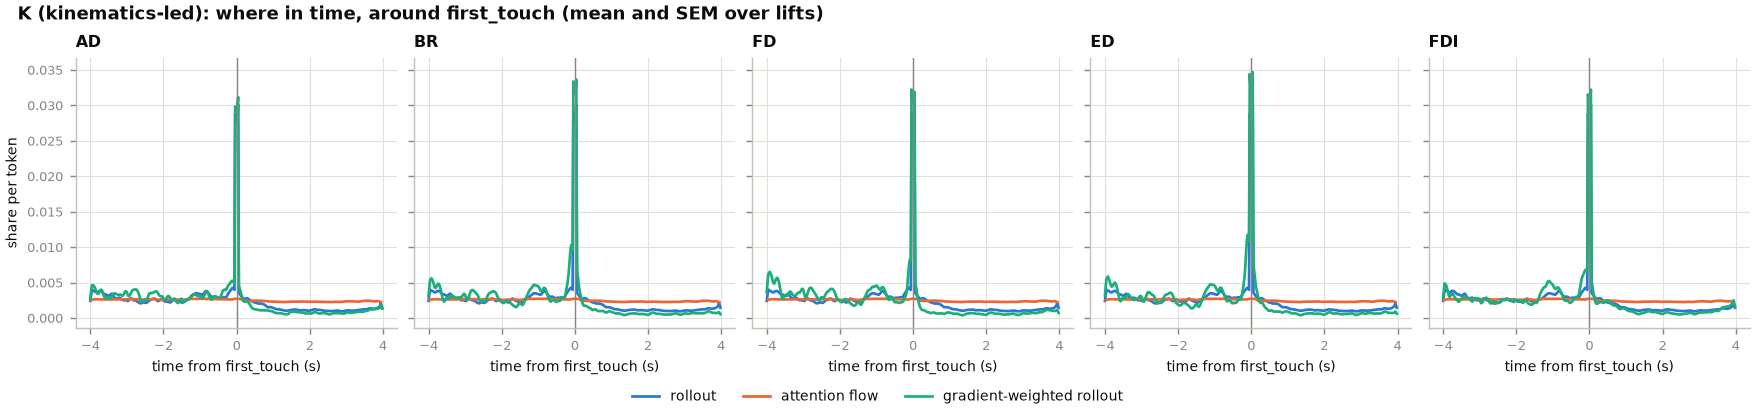

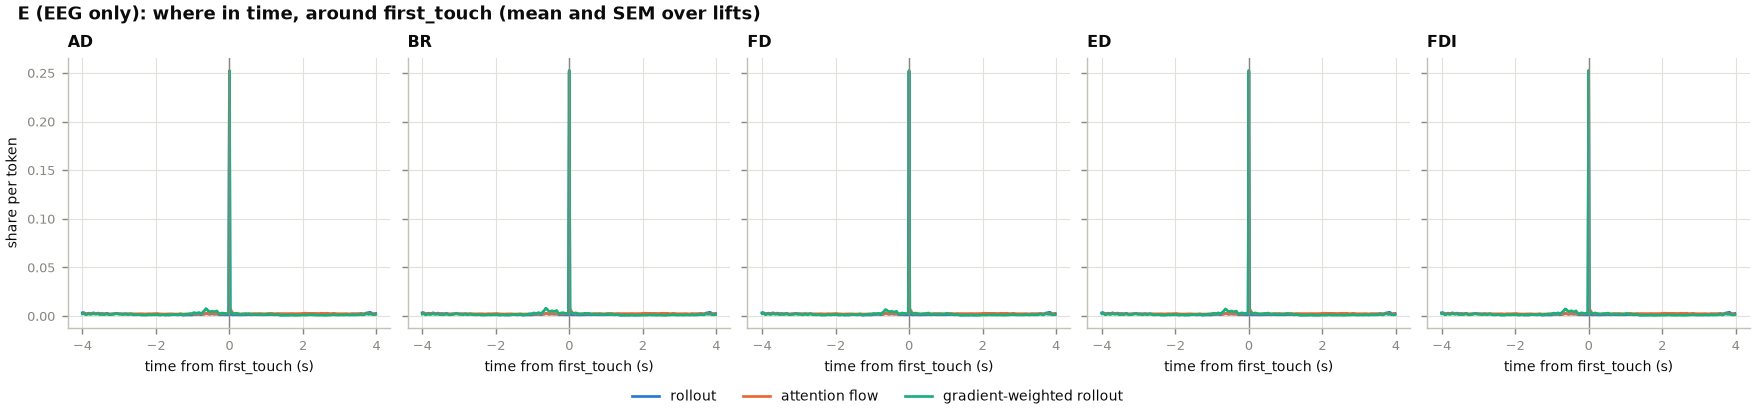

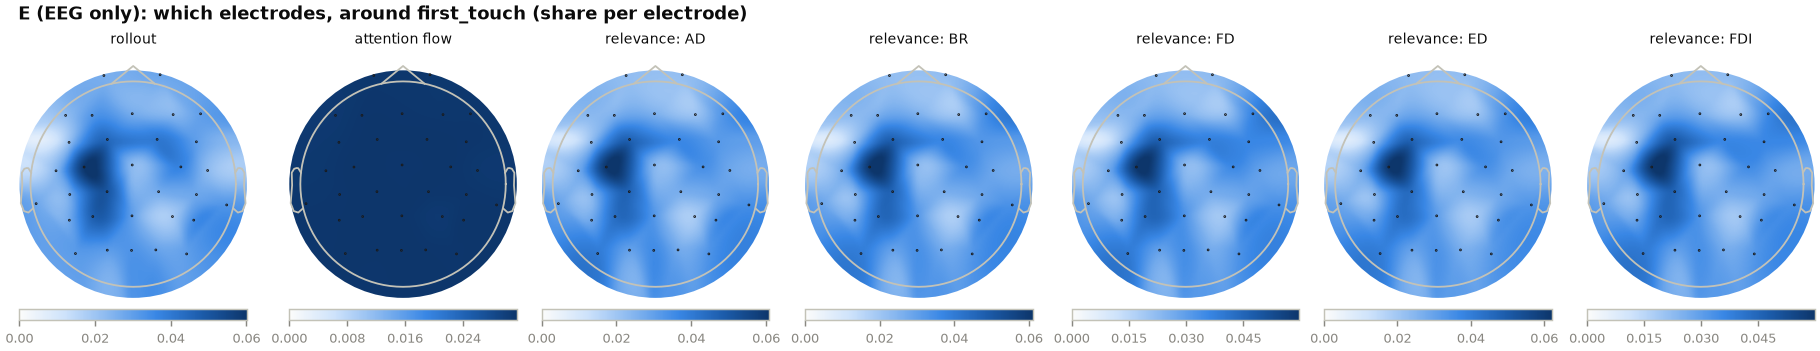

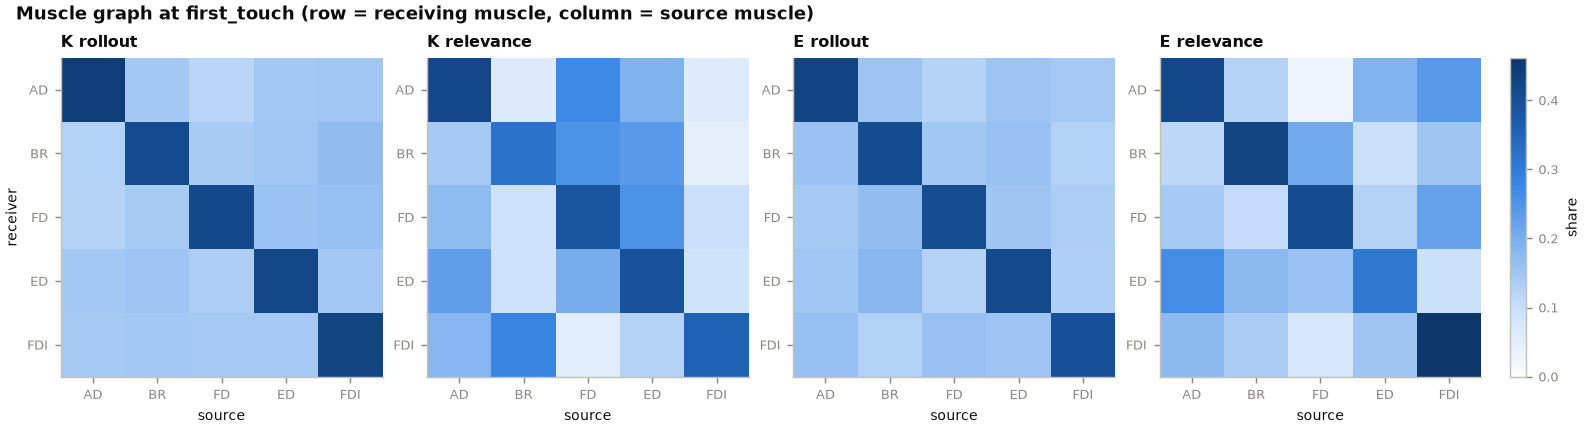

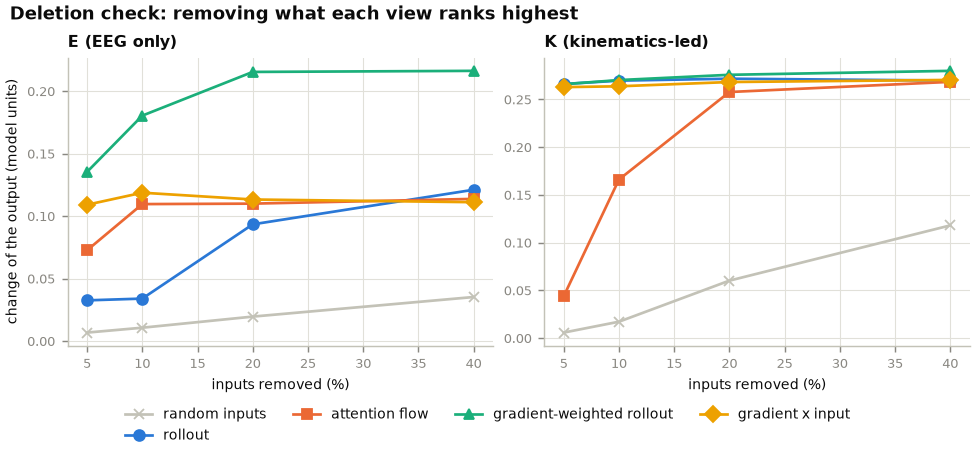


=== P12: 25 figures and 8 tables in outputs\interpretability_v2\P12, 4.2 min ===
exact parts of the outputs at the event token (mean over lifts):
muscle       event  n     K     E     F  K_base  gain  F_eeg
    AD first_touch 61 0.870 0.818 0.871   0.799 1.089  0.000
    BR first_touch 61 0.723 0.757 0.723   0.659 1.097 -0.001
    FD first_touch 61 0.917 0.875 0.920   0.785 1.169  0.002
    ED first_touch 61 0.797 0.766 0.798   0.705 1.132  0.001
   FDI first_touch 61 0.531 0.614 0.531   0.468 1.136 -0.000
    AD    lift_off 62 0.965 0.865 0.966   0.887 1.089  0.000
    BR    lift_off 62 0.929 0.843 0.928   0.847 1.096 -0.001
    FD    lift_off 62 0.951 0.912 0.953   0.815 1.168  0.002
    ED    lift_off 62 0.955 0.854 0.956   0.845 1.130  0.001
   FDI    lift_off 62 0.897 0.738 0.897   0.791 1.134  0.000
deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.
view      flow  relevance  rollout  saliency
output                     

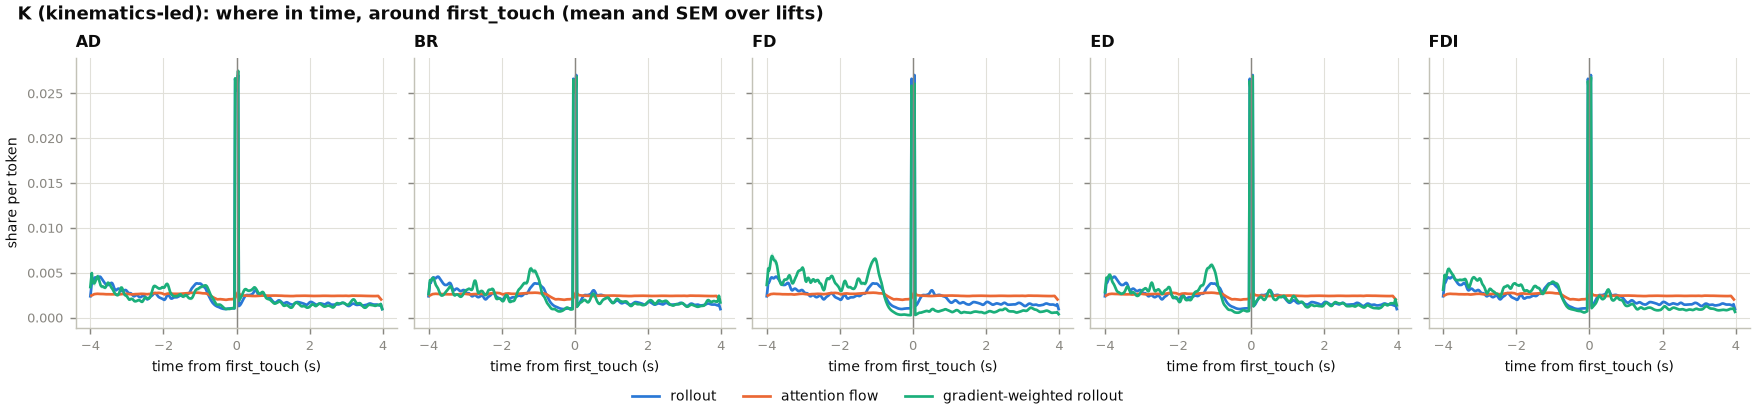

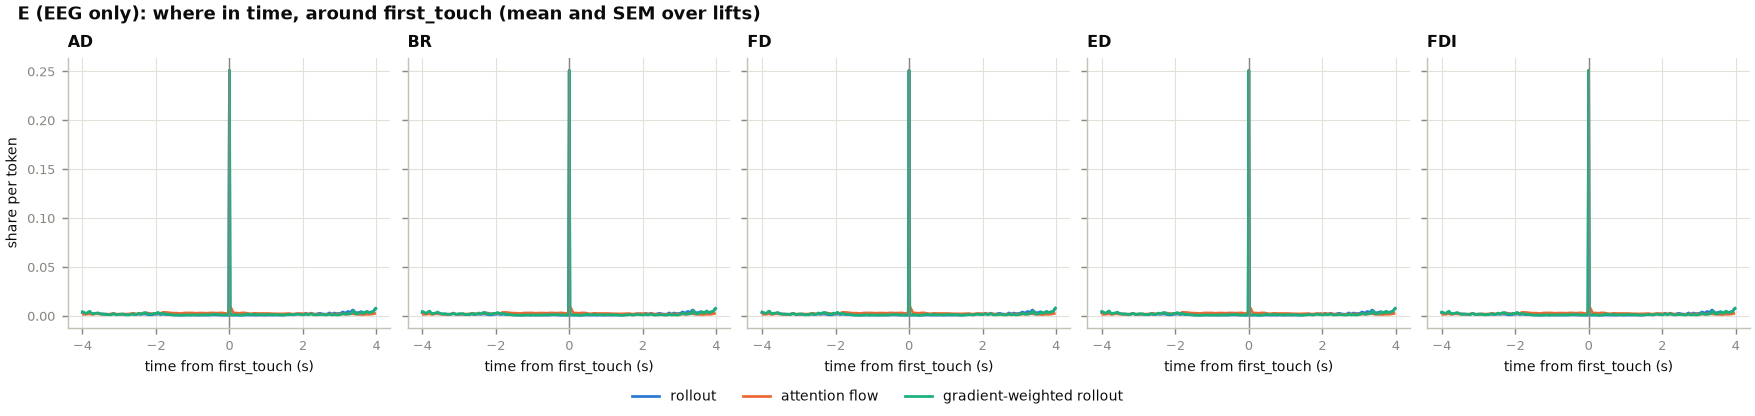

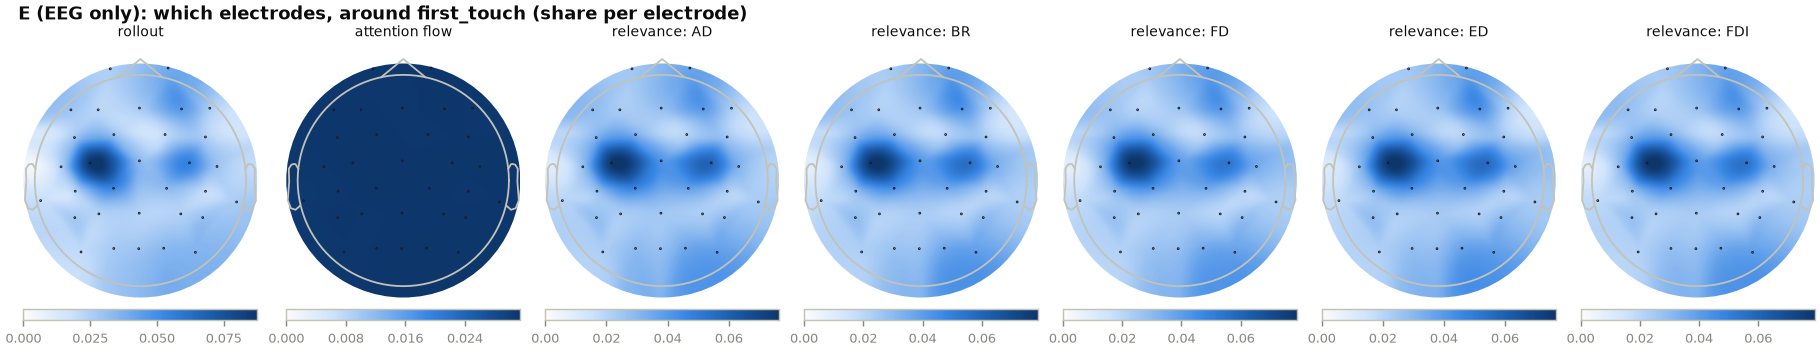

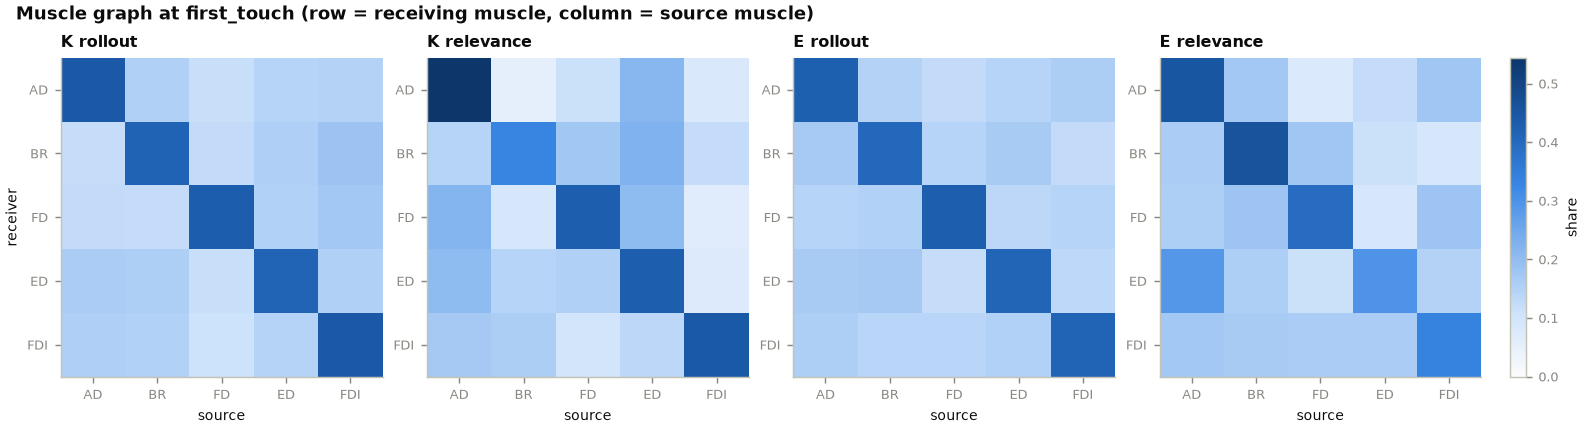

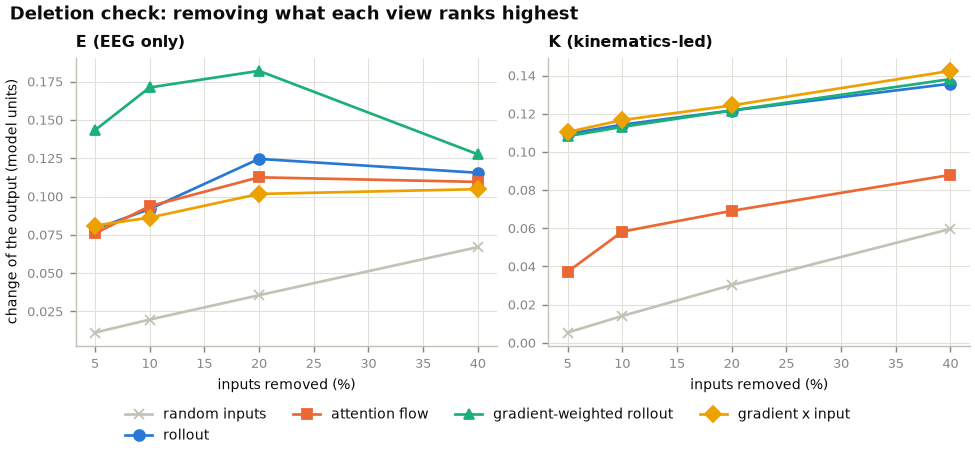

In [8]:
# V2-INTERP
# Where each output comes from, through every layer (see the Interpretability section of the first cell).
# One 8 s window is centred on every lift event of the test series; events are CONFIG["interp"]["events"].
# Reads the trained models of V2-TRAIN; writes tables and figures under CONFIG["outputs"]["interpretability_dir"].
INTERP_DIR = Path(CONFIG["outputs"]["interpretability_dir"])
kin_names = kin_feature_names(include_velocity=True, drop_indices=[12, 25], gated_force=True)
for subj, sd in subject_data.items():
    t0 = time.time()
    rep = interpret_subject(results[subj]["model"], sd["tokens"]["test"], sd["norm"], CONFIG, device, sd["p_id"],
                            sd["names"], out_dir=INTERP_DIR / subj, kin_names=kin_names)
    results[subj]["interp"] = rep
    tb = rep["tables"]
    print(f"\n=== {subj}: {len(rep.get('files', []))} figures and {len(tb)} tables in {INTERP_DIR / subj}, "
          f"{(time.time() - t0) / 60:.1f} min ===")
    if len(tb["parts"]):
        print("exact parts of the outputs at the event token (mean over lifts):")
        print(tb["parts"].round(3).to_string(index=False))
    if len(tb["faithfulness"]):
        f = tb["faithfulness"].assign(gain=lambda d: d["top"] - d["random"])
        print("deletion check: mean (top - random) change of the output. Above 0 = the view points at inputs the model uses.")
        print(f.groupby(["output", "view"])["gain"].mean().unstack().round(4).to_string())
        print("weight-shuffle check: Spearman between the maps of the trained and the shuffled model. Near 1 = the view ignores what was learned.")
        s = tb["sanity"]                             # spearman: mean over the events that have a map; n_nan = events without one
        print(s.groupby(["output", "view"])["spearman"].mean().unstack().round(2).to_string())
        if int(s["n_nan"].sum()):
            print(f"  {int(s['n_nan'].sum())} of {int(s['n'].sum())} map comparisons had no map (NaN), for example a closed fusion gate:")
            print(s[s["n_nan"] > 0].to_string(index=False))
    if len(tb["rest_contrast"]):
        rc = tb["rest_contrast"]                     # paired test: each lift against the rest after it
        testable = np.isfinite(rc["p"])              # p is NaN for an electrode that cannot be tested
        n_sig = int((testable & (rc["p"] < 0.05)).sum())
        print(f"rest contrast (E), {int(rc['n_pairs'].min())}-{int(rc['n_pairs'].max())} lift-rest pairs: {n_sig} of {int(testable.sum())} "
              f"testable muscle-electrode cells differ from rest (corrected p < 0.05); {int((~testable).sum())} not testable")
    event = CONFIG["interp"]["events"][0]
    for name in (f"time_K_{event}", f"time_E_{event}", f"scalp_E_{event}", f"muscle_graph_{event}", "deletion"):
        png = INTERP_DIR / subj / f"{name}.png"
        if png.exists():
            display(Image(filename=str(png)))